# AI Image FFT Detector - Colab runner

Run setup, then only the authorized phase. Phase 1 collects original files; Phase 2 audits and freezes splits. No classifier training yet. CPU only; all code is on main. Save actual outputs for team review.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## Clone the project
Clone main from the configured repository. An existing checkout is not overwritten; use a fresh session when you need a new checkout.

In [3]:
from pathlib import Path
import os
import subprocess

REPO_URL = "https://github.com/Rahul2-5/SpectraCheck.git"
PROJECT_DIR = Path("/content/ai-image-fft-detector")
if REPO_URL == "REPLACE_WITH_YOUR_GITHUB_REPOSITORY_URL":
    raise ValueError("Set REPO_URL to your GitHub repository URL first")

if PROJECT_DIR.exists():
    print(f"Directory {PROJECT_DIR} already exists. Skipping clone and pulling latest changes...")
    os.chdir(PROJECT_DIR)
    subprocess.run(["git", "pull"], check=True)
else:
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, str(PROJECT_DIR)], check=True)
    os.chdir(PROJECT_DIR)

print("Working directory:", Path.cwd())

Working directory: /content/ai-image-fft-detector


In [ ]:
%pip install -r /content/ai-image-fft-detector/requirements.txt
%pip install --no-deps -e /content/ai-image-fft-detector


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 45.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 115.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 125.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 130.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 57.1 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 133.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 131.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 32.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 47.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 23.3 MB/s  0:00:11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 112.7 MB/s  0:00:00
  Attempting uninstall: pytest
    Found existing installation: pytest 8.4.2
    Uninstalling pytest-8.4.2:
      Successfully uninstalled pytest-8.4.2
  At

Obtaining file:///content/ai-image-fft-detector
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ai-image-fft-detector (pyproject.toml) ... done
  Created wheel for ai-image-fft-detector: filename=ai_image_fft_detector-0.1.0-0.editable-py3-none-any.whl size=9657 sha256=9becd13046849bab5038df9a9c17b3bec1ce9e1fcc3abc71ef9fec1c9e0d6a45
  Stored in directory: /tmp/pip-ephem-wheel-cache-dfbnupn5/wheels/c9/05/2f/d6e4755b58ddf89231e97da982a277fc7911457522463e1f16
Successfully built ai-image-fft-detector


If Colab asks you to restart after installation, use Runtime > Restart session, then continue below (do not rerun the clone cell). This avoids mixing preloaded library versions with newly installed ones.

In [ ]:
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/ai-image-fft-detector")

SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from aidetect.io_utils import config_hash, load_config

cfg = load_config(PROJECT_DIR / "config.yaml")

print("Config SHA-256:", config_hash(cfg))
print("Package import: SUCCESS")

Config SHA-256: ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce
Package import: SUCCESS


In [ ]:
from pathlib import Path
import importlib
import importlib.metadata as metadata
import os
import platform
import subprocess
import sys

PROJECT_DIR = Path("/content/ai-image-fft-detector")
os.chdir(PROJECT_DIR)
print("Python:", platform.python_version())
print("Branch:", subprocess.check_output(["git", "branch", "--show-current"], text=True).strip())
print("Commit:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())

# Run pip check but capture any error peacefully instead of failing
result = subprocess.run([sys.executable, "-m", "pip", "check"], capture_output=True, text=True)
if result.returncode != 0:
    print("\n[WARNING] pip check returned non-zero code. Dependency conflicts exist:")
    print(result.stdout or result.stderr)
else:
    print("pip check: OK")

modules = {"pillow": "PIL", "scikit-learn": "sklearn", "pyyaml": "yaml", "imagehash": "imagehash", "huggingface-hub": "huggingface_hub"}
for line in (PROJECT_DIR / "requirements.txt").read_text().splitlines():
    if not line.strip() or line.startswith("#"):
        continue
    package, expected = line.split("==")
    installed = metadata.version(package)
    assert installed == expected, f"Version mismatch: {package}: {installed} != {expected}"
    importlib.import_module(modules.get(package, package))
    print(f"{package}=={installed}")

from aidetect.io_utils import config_hash, load_config
cfg = load_config("config.yaml")
print("Config SHA-256:", config_hash(cfg))

Python: 3.13.18
Branch: main
Commit: 673d9773a5d69e253aeb187b1482e832872e600e

[WARNING] pip check returned non-zero code. Dependency conflicts exist:
ipython 7.34.0 requires jedi, which is not installed.
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 3.1.0.

numpy==2.4.6
scipy==1.17.1
pandas==3.1.0
pyarrow==26.0.0
pillow==13.0.0
scikit-learn==1.9.1
xgboost==3.2.0
statsmodels==0.15.0
imagehash==4.3.2
matplotlib==3.11.2
datasets==5.1.0
huggingface-hub==2.3.0
pyyaml==6.0.3
joblib==1.6.0
pytest==9.1.1
fastapi==0.162.0
uvicorn==0.54.0
httpx==0.28.1
Config SHA-256: ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT_DIR / "src")

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=PROJECT_DIR,
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0
........................................................................ [ 47%]
........................................................................ [ 94%]
.........                                                                [100%]
153 passed in 62.27s (0:01:02)




In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT_DIR / "src")

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=PROJECT_DIR,
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\n--- STDOUT ---")
print(result.stdout)
print("\n--- STDERR ---")
print(result.stderr)

Return code: 0

--- STDOUT ---
........................................................................ [ 47%]
........................................................................ [ 94%]
.........                                                                [100%]
153 passed in 25.71s


--- STDERR ---



In [ ]:
import os
import sys
import subprocess

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT_DIR / "src")

subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=PROJECT_DIR, env=env, check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q'], returncode=0)

## Phase 0 review
Record setup results and check GitHub Actions. If Phase 1 has been authorized, continue below; otherwise stop here.

## Phase 1 - Original image collection
Download CIFAKE manually from [Kaggle](https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images) and extract it on Drive. Set the folder below to the parent of train/REAL, train/FAKE, test/REAL, test/FAKE. The pilot is separate from main data. Keep this session on CPU.

In [ ]:
%pip install -U kaggle

  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    "Paste your NEW Kaggle token: "
)

!kaggle --version

Paste your NEW Kaggle token: ··········
Kaggle CLI 2.2.5


In [ ]:
!kaggle datasets download \
  -d birdy654/cifake-real-and-ai-generated-synthetic-images \
  -p /content/cifake-download \
  --unzip

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 168MB/s] 



In [ ]:
from pathlib import Path

root = Path("/content/cifake-download")

print("Download folder exists:", root.exists())

for p in list(root.iterdir())[:20]:
    print("DIR " if p.is_dir() else "FILE", p.name)

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".webp"
    }
]

print("\nTotal image files found:", len(images))
print("Sample image paths:")
for p in images[:5]:
    print(p)

Download folder exists: True
DIR  test
DIR  train

Total image files found: 120000
Sample image paths:
/content/cifake-download/train/REAL/3905 (7).jpg
/content/cifake-download/train/REAL/2616 (6).jpg
/content/cifake-download/train/REAL/2459 (2).jpg
/content/cifake-download/train/REAL/1451 (9).jpg
/content/cifake-download/train/REAL/2825 (2).jpg


In [ ]:
from pathlib import Path

root = Path("/content/cifake-download")

for split in ["train", "test"]:
    print(f"\n{split.upper()}")
    for label in ["REAL", "FAKE"]:
        folder = root / split / label
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".webp"}
        ) if folder.exists() else 0
        print(f"{label}: {count:,} images")

print("\nDataset root:", root)


TRAIN
REAL: 50,000 images
FAKE: 50,000 images

TEST
REAL: 10,000 images
FAKE: 10,000 images

Dataset root: /content/cifake-download


In [ ]:
import os
import sys
import subprocess
from pathlib import Path

CIFAKE_SOURCE_DIR = Path("/content/cifake-download")

if not CIFAKE_SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"CIFAKE folder not found: {CIFAKE_SOURCE_DIR}"
    )

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT_DIR / "src")

result = subprocess.run(
    [
        sys.executable,
        "scripts/download_pilot.py",
        "--source-dir",
        str(CIFAKE_SOURCE_DIR),
    ],
    cwd=PROJECT_DIR,
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\n--- STDOUT ---")
print(result.stdout)
print("\n--- STDERR ---")
print(result.stderr)

if result.returncode != 0:
    raise subprocess.CalledProcessError(result.returncode, result.args, output=result.stdout, stderr=result.stderr)

Return code: 0

--- STDOUT ---
Source generator counts: {"Real": 60000, "SD14": 60000}
Saved images: {"ai": 500, "real": 500}
Pilot manifest: /content/drive/MyDrive/aidetect/data/pilot/manifest.csv


--- STDERR ---



### Main collection
The next command scans Tiny-GenImage metadata, counts every generator, then saves only SD15 images and a random sample of real images. It may transfer the full upstream Parquet dataset; a subset does not guarantee a small download. Rerun after a disconnection to reuse unchanged saved files. Exit code 2 means the SD15 count is too small: outputs are saved, but consult the supervisor before Phase 2.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

project = Path("/content/ai-image-fft-detector")
assert (project / "scripts/download_main.py").is_file(), "Run the clone/setup cells first."

env = os.environ.copy()
env["PYTHONPATH"] = str(project / "src")

result = subprocess.run(
    [sys.executable, "-u", "scripts/download_main.py"],
    cwd=project,
    env=env,
)

print("DOWNLOAD RETURN CODE:", result.returncode)

DOWNLOAD RETURN CODE: 0


In [ ]:
import json
from pathlib import Path

main_dir = Path("/content/drive/MyDrive/aidetect/data/main")

record = json.loads(
    (main_dir / "acquisition.json").read_text()
)

print(json.dumps(record, indent=2))

{
  "generator_counts": {
    "ADM": 2500,
    "BigGAN": 2500,
    "GLIDE": 2500,
    "Midjourney": 2500,
    "Real": 17500,
    "SD14": 0,
    "SD15": 2500,
    "VQDM": 2500,
    "Wukong": 2500
  },
  "manifest_sha256": "61270a3c51cc70a8059407c1a705549b363f9c5ef11ec497685d94b853c0be61",
  "saved_counts": {
    "ai": 2500,
    "real": 4000
  },
  "schemas": {
    "train": {
      "generators": [
        "Real",
        "ADM",
        "BigGAN",
        "GLIDE",
        "Midjourney",
        "SD14",
        "SD15",
        "VQDM",
        "Wukong"
      ],
      "labels": [
        "real",
        "fake"
      ],
      "real_id": 0,
      "target_id": 6
    },
    "validation": {
      "generators": [
        "Real",
        "ADM",
        "BigGAN",
        "GLIDE",
        "Midjourney",
        "SD14",
        "SD15",
        "VQDM",
        "Wukong"
      ],
      "labels": [
        "real",
        "fake"
      ],
      "real_id": 0,
      "target_id": 6
    }
  },
  "specification": 

In [ ]:
result = subprocess.run(
    [
        sys.executable,
        "-u",
        "scripts/download_main.py"
    ],
    cwd=PROJECT_DIR,
    env=env,
    check=False
)

print("Return code:", result.returncode)

Return code: 0


In [ ]:
exec("from pathlib import Path\nr = Path(\"/content/drive/MyDrive/aidetect\")\nfor d in (r / \"metadata_diagnostic\", r / \"geometry_diagnostic\"):\n    print(\"DIRECTORY\", d)\n    if d.is_dir():\n        print(\"FILES\", sorted(p.name for p in d.iterdir() if p.is_file()))\n        for p in sorted(d.glob(\"*.md\")):\n            print(\"REPORT\", p.name, \"\\n\", p.read_text())\np = r / \"data/audit/audit_result.json\"\nprint(\"AUDIT\", p.read_text() if p.is_file() else \"MISSING\")\nprint(\"CONFIG PATHS\", cfg.get(\"paths\"))\nfor q in (Path(\"/content/drive\"), r, r / \"data\", Path(\"/content/ai-image-fft-detector/reports\")):\n    print(\"PATH\", q, \"EXISTS\", q.exists())\n    if q.is_dir():\n        print(\"ENTRIES\", sorted(p.name for p in q.iterdir())[:35])")

DIRECTORY /content/drive/MyDrive/aidetect/metadata_diagnostic
DIRECTORY /content/drive/MyDrive/aidetect/geometry_diagnostic
AUDIT MISSING
CONFIG PATHS {'data_root': '/content/drive/MyDrive/aidetect/data', 'features_root': '/content/drive/MyDrive/aidetect/features', 'reports_root': 'reports', 'artifacts_root': 'artifacts'}
PATH /content/drive EXISTS True
ENTRIES ['.Encrypted', '.Trash-0', '.shortcut-targets-by-id', 'MyDrive']
PATH /content/drive/MyDrive/aidetect EXISTS True
ENTRIES ['.ipynb_checkpoints', 'data', 'features']
PATH /content/drive/MyDrive/aidetect/data EXISTS True
ENTRIES ['main', 'pilot']
PATH /content/ai-image-fft-detector/reports EXISTS True
ENTRIES ['phase_0_environment.json', 'phase_0_report.md', 'phase_1_checks.json', 'phase_1_report.md', 'phase_2_checks.json', 'phase_2_report.md', 'phase_3_checks.json', 'phase_3_report.md', 'phase_4_checks.json', 'phase_4_report.md', 'phase_5_checks.json', 'phase_5_report.md', 'phase_6_checks.json', 'phase_6_report.md', 'phase_7_chec

In [ ]:
import json
from pathlib import Path

main_dir = Path("/content/drive/MyDrive/aidetect/data/main")

record = json.loads(
    (main_dir / "acquisition.json").read_text()
)

print(json.dumps(record, indent=2))

{
  "generator_counts": {
    "ADM": 2500,
    "BigGAN": 2500,
    "GLIDE": 2500,
    "Midjourney": 2500,
    "Real": 17500,
    "SD14": 0,
    "SD15": 2500,
    "VQDM": 2500,
    "Wukong": 2500
  },
  "manifest_sha256": "61270a3c51cc70a8059407c1a705549b363f9c5ef11ec497685d94b853c0be61",
  "saved_counts": {
    "ai": 2500,
    "real": 4000
  },
  "schemas": {
    "train": {
      "generators": [
        "Real",
        "ADM",
        "BigGAN",
        "GLIDE",
        "Midjourney",
        "SD14",
        "SD15",
        "VQDM",
        "Wukong"
      ],
      "labels": [
        "real",
        "fake"
      ],
      "real_id": 0,
      "target_id": 6
    },
    "validation": {
      "generators": [
        "Real",
        "ADM",
        "BigGAN",
        "GLIDE",
        "Midjourney",
        "SD14",
        "SD15",
        "VQDM",
        "Wukong"
      ],
      "labels": [
        "real",
        "fake"
      ],
      "real_id": 0,
      "target_id": 6
    }
  },
  "specification": 

In [ ]:
import pandas as pd

manifest = pd.read_csv(main_dir / "manifest.csv")

print("Total images:", len(manifest))
print("\nLabel counts:")
print(manifest.groupby("label").size())

print("\nGenerator counts:")
print(manifest.groupby("generator").size())

Total images: 6500

Label counts:
label
0    4000
1    2500
dtype: int64

Generator counts:
generator
Real    4000
SD15    2500
dtype: int64


In [ ]:
import json
import pandas as pd
from PIL import Image as PILImage
from IPython.display import display

cfg = load_config(PROJECT_DIR / "config.yaml")
for collection in ("pilot", "main"):
    root = Path(cfg["paths"]["data_root"]) / collection
    manifest = pd.read_csv(root / "manifest.csv")
    record = json.loads((root / "acquisition.json").read_text())
    assert record["status"] == "complete", "Acquisition did not finish"
    listed = set(manifest["rel_path"])
    actual = {p.relative_to(root).as_posix() for folder in ("real", "ai") for p in (root / folder).glob("*") if p.is_file() and p.suffix != ".tmp"}
    assert len(manifest) == len(listed) and listed == actual, "Manifest/file counts differ"
    assert all((root / row.rel_path).stat().st_size == row.n_bytes for row in manifest.itertuples())
    print(collection, "saved counts:", manifest.groupby("label").size().to_dict())
    print(collection, "source generator counts:", record["generator_counts"])
    if collection == "main":
        assert record["saved_counts"]["ai"] >= cfg["dataset"]["minimum_ai_images"], "STOP: ask supervisor about insufficient SD15 data"
        print("Record SD15 and SD14 counts in the team tracker.")
    for label in (0, 1):
        samples = manifest[manifest["label"] == label].sample(n=5, random_state=cfg["seed"])
        for relative in samples["rel_path"]:
            with PILImage.open(root / relative) as image:
                image.load()
                print(collection, "label", label, relative, image.size, image.format)
                display(image.copy())


pilot saved counts: {0: 500, 1: 500}
pilot source generator counts: {'Real': 60000, 'SD14': 60000}
pilot label 0 real/train_0_361.jpg (32, 32) JPEG


<PIL.Image.Image image mode=RGB size=32x32>

pilot label 0 real/test_0_73.jpg (32, 32) JPEG


<PIL.Image.Image image mode=RGB size=32x32>

pilot label 0 real/train_0_374.jpg (32, 32) JPEG


...

<PIL.Image.Image image mode=RGB size=512x512>

main label 1 ai/validation_4027.png (512, 512) PNG


<PIL.Image.Image image mode=RGB size=512x512>

main label 1 ai/train_21527.png (512, 512) PNG


<PIL.Image.Image image mode=RGB size=512x512>

## Phase 1 review
Confirm generator counts, supervisor decision if SD15 is below the configured minimum, matching manifest/file counts, and five readable images per class. Continue only if Phase 2 is authorized. Keep real-data checks pending when their outputs are not available.

## Phase 2 - Audit before building the detector
Use the complete main collection already on Drive. Skip Phase 1 commands if it is already downloaded. The audit measures file format, quality and size, excludes undersized images before freezing, balances classes, and tests metadata-only shortcuts. It preserves originals. If a probe still exceeds 0.60 after the preplanned fix, STOP and review the report; do not weaken the threshold.

In [ ]:
result = subprocess.run(
    [sys.executable, "-u", "scripts/run_audit.py"],
    cwd=PROJECT_DIR,
    env=env,
    check=False
)

print("Return code:", result.returncode)

Return code: 2


In [ ]:
exec("from pathlib import Path\nimport json, os, subprocess, sys, shutil\nproject = Path(\"/content/ai-image-fft-detector\")\nroot = Path(\"/content/drive/MyDrive/aidetect\")\nrunenv = os.environ.copy()\nrunenv[\"PYTHONPATH\"] = str(project / \"src\")\nfor args in ([sys.executable, \"-m\", \"pytest\", \"-q\"], [sys.executable, \"-m\", \"pip\", \"check\"]):\n    checked = subprocess.run(args, cwd=project, env=runenv, capture_output=True, text=True)\n    print(\"CHECK\", args, \"EXIT\", checked.returncode, flush=True)\n    print(checked.stdout, checked.stderr, flush=True)\naudit_file = root / \"data/audit/audit_result.json\"\naudit = json.loads(audit_file.read_text())\nprint(\"FRESH AUDIT\", json.dumps(audit, indent=2), flush=True)\nbackup = root / \"phase_2_live_review\"\nbackup.mkdir(exist_ok=True)\nreport = project / \"reports/audit_report.md\"\nif report.is_file():\n    shutil.copy2(report, backup / report.name)\nif audit.get(\"status\") == \"blocked\":\n    for script, folder in ((\"diagnose_metadata_shortcut.py\", \"metadata_diagnostic\"), (\"diagnose_geometry_bins.py\", \"geometry_diagnostic\")):\n        args = [sys.executable, \"-u\", str(project / \"scripts\" / script), \"--data-root\", str(root / \"data\"), \"--output-dir\", str(root / folder), \"--config\", str(project / \"config.yaml\")]\n        checked = subprocess.run(args, cwd=project, env=runenv, capture_output=True, text=True)\n        print(\"DIAGNOSTIC\", script, \"EXIT\", checked.returncode, flush=True)\n        print(checked.stdout, checked.stderr, flush=True)\n        for p in sorted((root / folder).glob(\"*.md\")):\n            print(\"REPORT\", p.name, \"\\n\", p.read_text(), flush=True)\nprint(\"Verification complete. No split creation, training, freeze or evaluation was run.\", flush=True)")

CHECK ['/usr/bin/python3', '-m', 'pytest', '-q'] EXIT 0
........................................................................ [ 47%]
........................................................................ [ 94%]
.........                                                                [100%]
153 passed in 25.81s
 
CHECK ['/usr/bin/python3', '-m', 'pip', 'check'] EXIT 1
ipython 7.34.0 requires jedi, which is not installed.
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 3.1.0.
 
FRESH AUDIT {
  "active_manifest_sha256": "db7b72907e8b0de7b5aa343a654c59aaee9b945080a4fd7c6122852abbc5cb81",
  "balanced_rows": 5000,
  "before_probe": {
    "columns": [
      "is_jpeg",
      "jpeg_quality",
      "width",
      "height",
      "n_bytes",
      "aspect_ratio"
    ],
    "counts": {
      "0": 2500,
      "1": 2500
    },
    "cv_folds": 5,
    "max_accuracy": 1.0,
    "models": {
      "decision_tree": {
        "fold_accuracies": [
          1.0,
          1.0,
     

# Dataset audit report

Status: **blocked**
Config SHA-256: `ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce`

Probe rule: BOTH metadata-only CV mean accuracies must be <= 0.60. Probes use balanced eligible classes; source splits are not final experiment splits.
JPEG quality is a nearest-standard quantization-table estimate; a residual above zero means the match is approximate.
Labels: real = 0, AI-generated = 1. Originals remain unchanged on disk.
Passing this probe does not prove all confounding is removed.

## Original files

```text
format  JPEG   PNG
label             
0       4000     0
1          0  2500

       count  median_width  median_height  jpeg_count  median_jpeg_quality  max_quality_table_mae
label                                                                                            
0       4000         500.0          375.0        4000                 96.0               0.609375
1       2500         512.0          512.0           0                  NaN                    NaN
```


## Before files

```text
format  JPEG   PNG
label             
0       2500     0
1          0  2500

       count  median_width  median_height  jpeg_count  median_jpeg_quality  max_quality_table_mae
label                                                                                            
0       2500         500.0          375.0        2500                 96.0                    0.0
1       2500         512.0          512.0           0                  NaN                    NaN
```


## Active files

```text
format  JPEG
label       
0       2500
1       2500

       count  median_width  median_height  jpeg_count  median_jpeg_quality  max_quality_table_mae
label                                                                                            
0       2500         500.0          375.0        2500                 96.0                    0.0
1       2500         512.0          512.0        2500                 96.0                    0.0
```


## Decisions and counts

```json
{
  "active_manifest_sha256": "db7b72907e8b0de7b5aa343a654c59aaee9b945080a4fd7c6122852abbc5cb81",
  "balanced_rows": 5000,
  "before_probe": {
    "columns": [
      "is_jpeg",
      "jpeg_quality",
      "width",
      "height",
      "n_bytes",
      "aspect_ratio"
    ],
    "counts": {
      "0": 2500,
      "1": 2500
    },
    "cv_folds": 5,
    "max_accuracy": 1.0,
    "models": {
      "decision_tree": {
        "fold_accuracies": [
          1.0,
          1.0,
          1.0,
          1.0,
          1.0
        ],
        "mean_accuracy": 1.0
      },
      "logistic_regression": {
        "fold_accuracies": [
          1.0,
          1.0,
          0.999,
          1.0,
          1.0
        ],
        "mean_accuracy": 0.9998000000000001
      }
    }
  },
  "config_hash": "ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce",
  "duplicate_groups": 0,
  "eligible_rows": 6148,
  "exact_duplicate_groups": 0,
  "excluded_rows": 1500,
  "exclusion_reasons": {
    "excess_real_for_balance": 1148,
    "smaller_than_target": 352
  },
  "final_probe": {
    "columns": [
      "is_jpeg",
      "jpeg_quality",
      "width",
      "height",
      "n_bytes",
      "aspect_ratio"
    ],
    "counts": {
      "0": 2500,
      "1": 2500
    },
    "cv_folds": 5,
    "max_accuracy": 0.9998000000000001,
    "models": {
      "decision_tree": {
        "fold_accuracies": [
          1.0,
          1.0,
          1.0,
          0.999,
          1.0
        ],
        "mean_accuracy": 0.9998000000000001
      },
      "logistic_regression": {
        "fold_accuracies": [
          0.833,
          0.84,
          0.836,
          0.828,
          0.817
        ],
        "mean_accuracy": 0.8308
      }
    }
  },
  "mixed_label_groups": 0,
  "normalization_applied": true,
  "original_rows": 6500,
  "remediation_error": null,
  "specification": {
    "config_hash": "ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce",
    "source_manifest_sha256": "61270a3c51cc70a8059407c1a705549b363f9c5ef11ec497685d94b853c0be61"
  },
  "status": "blocked",
  "target_jpeg_quality": 96,
  "threshold": 0.6
}
```

If blocked, stop. Do not weaken the threshold or create splits to bypass the result.
No frequency features or classifier test-set performance were inspected.

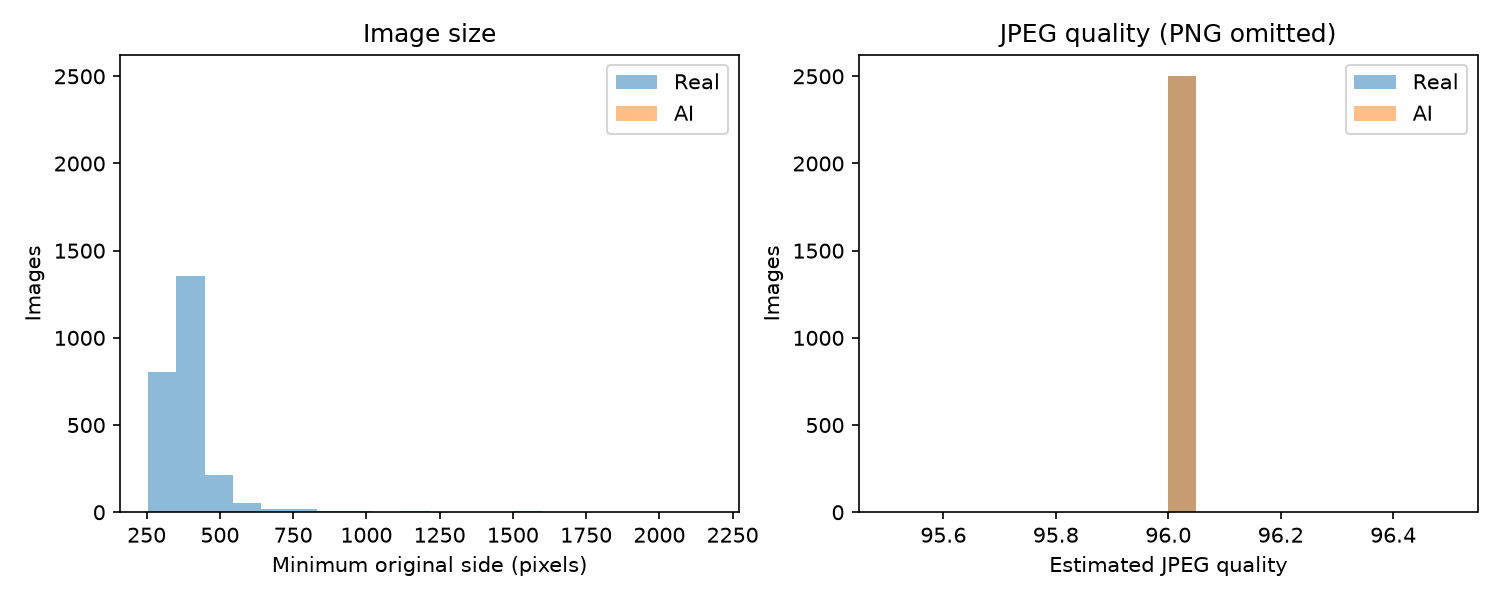

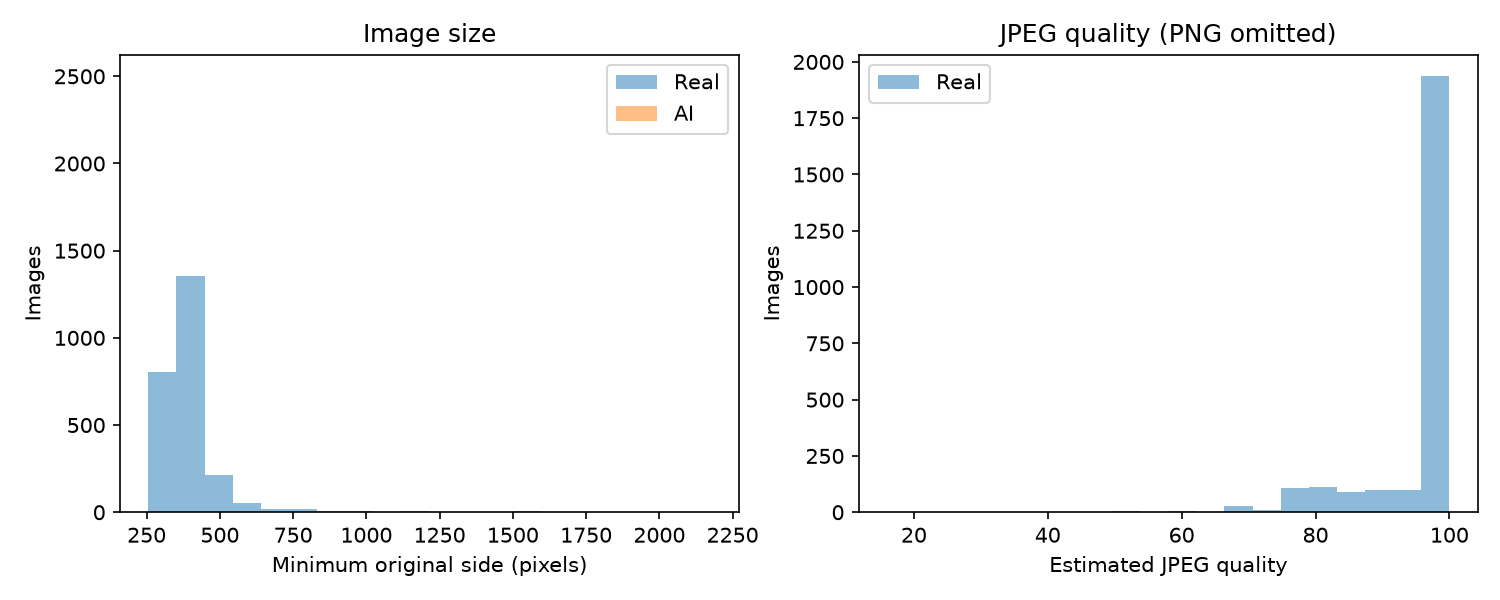

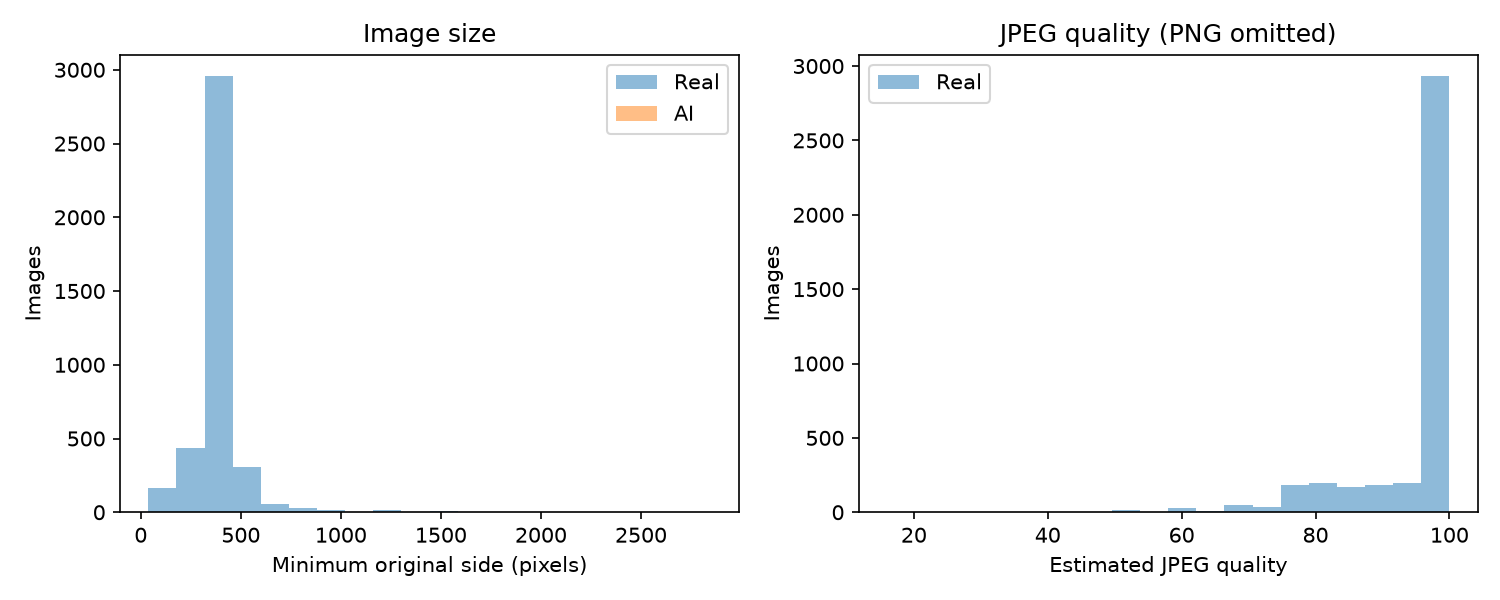

In [ ]:
from IPython.display import Markdown, Image as DisplayImage, display

cfg = load_config(PROJECT_DIR / "config.yaml")
REPORTS_DIR = Path(cfg["paths"]["reports_root"])
report_text = (REPORTS_DIR / "audit_report.md").read_text()
display(Markdown(chr(10).join(line for line in report_text.splitlines() if not line.startswith("!["))))
for figure in sorted((REPORTS_DIR / "figures").glob("audit_*.png")):
    display(DisplayImage(filename=str(figure)))


In [ ]:
import os
import subprocess
import sys

PROJECT_DIR = "/content/ai-image-fft-detector"

os.chdir(PROJECT_DIR)

env = os.environ.copy()
env["PYTHONPATH"] = str(os.path.join(PROJECT_DIR, "src"))

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "scripts/diagnose_metadata_shortcut.py",
        "--data-root",
        "/content/drive/MyDrive/aidetect/data",
        "--output-dir",
        "/content/drive/MyDrive/aidetect/metadata_diagnostic",
        "--config",
        "config.yaml",
    ],
    env=env,
    text=True,
)

print("Return code:", result.returncode)

Return code: 0


In [ ]:
%cd /content/ai-image-fft-detector
!git pull

/content
Already up to date.


In [ ]:
import os
import subprocess
import sys

PROJECT_DIR = "/content/ai-image-fft-detector"
os.chdir(PROJECT_DIR)

env = os.environ.copy()
env["PYTHONPATH"] = os.path.join(PROJECT_DIR, "src")

result = subprocess.run(
    [
        sys.executable, "-u",
        "scripts/diagnose_metadata_shortcut.py",
        "--data-root", "/content/drive/MyDrive/aidetect/data",
        "--output-dir", "/content/drive/MyDrive/aidetect/metadata_diagnostic",
        "--config", "config.yaml",
    ],
    env=env,
    capture_output=True,
    text=True,
)

print("RETURN CODE:", result.returncode)
print("\n--- STDOUT ---")
print(result.stdout)
print("\n--- STDERR ---")
print(result.stderr)

RETURN CODE: 0

--- STDOUT ---
{
  "make_splits_called": false,
  "output_dir": "/content/drive/MyDrive/aidetect/metadata_diagnostic",
  "status": "completed"
}


--- STDERR ---



In [ ]:
%cd /content/ai-image-fft-detector
!git pull

/content
Already up to date.


In [ ]:
%cd /content/ai-image-fft-detector
!git pull

/content
Already up to date.


In [ ]:
import os
import subprocess
import sys

PROJECT_DIR = "/content/ai-image-fft-detector"
os.chdir(PROJECT_DIR)

env = os.environ.copy()
env["PYTHONPATH"] = os.path.join(PROJECT_DIR, "src")

result = subprocess.run(
    [
        sys.executable, "-u",
        "scripts/diagnose_geometry_bins.py",
        "--data-root", "/content/drive/MyDrive/aidetect/data",
        "--output-dir", "/content/drive/MyDrive/aidetect/geometry_diagnostic",
        "--scope", "active",
        "--config", "config.yaml",
    ],
    env=env,
    capture_output=True,
    text=True,
)

print("Return code:", result.returncode)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

Return code: 0
STDOUT: {
  "output_dir": "/content/drive/MyDrive/aidetect/geometry_diagnostic",
  "splits_created": false,
  "status": "completed"
}

STDERR: 


In [ ]:
exec("from pathlib import Path\nimport json, os, subprocess, sys\nfrom aidetect.io_utils import load_config, config_hash\nproject = Path(\"/content/ai-image-fft-detector\")\nsettings = load_config(project / \"config.yaml\")\naudit_path = Path(settings[\"paths\"][\"data_root\"]) / \"audit/audit_result.json\"\naudit = json.loads(audit_path.read_text()) if audit_path.is_file() else {}\nif audit.get(\"status\") != \"passed\" or audit.get(\"config_hash\") != config_hash(settings):\n    print(\"BLOCKED - no research splits were created.\")\n    print(\"Audit status:\", audit.get(\"status\", \"missing\"))\n    print(\"Required maximum accuracy:\", settings[\"audit\"][\"shortcut_max_accuracy\"])\n    for name, values in audit.get(\"final_probe\", {}).get(\"models\", {}).items():\n        print(name, \"CV accuracy:\", values[\"mean_accuracy\"])\n    print(\"Identical JPEG encoding did not remove the geometry shortcut. Review the dataset decision with the team/supervisor before proceeding.\")\n    print(\"Reports: /content/drive/MyDrive/aidetect/metadata_diagnostic and /content/drive/MyDrive/aidetect/geometry_diagnostic\")\nelse:\n    split_env = os.environ.copy()\n    split_env[\"PYTHONPATH\"] = str(project / \"src\")\n    checked = subprocess.run([sys.executable, \"scripts/make_splits.py\"], cwd=project, env=split_env, capture_output=True, text=True)\n    print(checked.stdout, checked.stderr)\n    checked.check_returncode()")

BLOCKED - no research splits were created.
Audit status: blocked
Required maximum accuracy: 0.6
decision_tree CV accuracy: 0.9998000000000001
logistic_regression CV accuracy: 0.8308
Identical JPEG encoding did not remove the geometry shortcut. Review the dataset decision with the team/supervisor before proceeding.
Reports: /content/drive/MyDrive/aidetect/metadata_diagnostic and /content/drive/MyDrive/aidetect/geometry_diagnostic


In [ ]:
exec("import importlib.util, importlib.metadata as metadata, subprocess, sys\nfrom pathlib import Path\nif importlib.util.find_spec(\"jedi\") is None:\n    installed = subprocess.run([sys.executable, \"-m\", \"pip\", \"install\", \"jedi==0.19.2\"], capture_output=True, text=True)\n    print(installed.stdout, installed.stderr, flush=True)\n    installed.check_returncode()\nprint(\"jedi:\", metadata.version(\"jedi\"), flush=True)\nchecked = subprocess.run([sys.executable, \"-m\", \"pip\", \"check\"], capture_output=True, text=True)\nprint(\"pip check exit:\", checked.returncode, flush=True)\nprint(checked.stdout, checked.stderr, flush=True)\nif checked.returncode:\n    print(\"UNRESOLVED: Colab expects pandas 2.2.3; the research requirements pin pandas 3.1.0. Research pins were preserved. This is not a passing dependency check.\", flush=True)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 17.7 MB/s  0:00:00
 
jedi: 0.19.2
pip check exit: 1
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 3.1.0.
 
UNRESOLVED: Colab expects pandas 2.2.3; the research requirements pin pandas 3.1.0. Research pins were preserved. This is not a passing dependency check.


In [ ]:
import json
import pandas as pd
from aidetect.io_utils import sha256_of_file

DATA_ROOT = Path(cfg["paths"]["data_root"])
ARTIFACTS_DIR = Path(cfg["paths"]["artifacts_root"])
audit_result = json.loads((DATA_ROOT / "audit/audit_result.json").read_text())
assert audit_result["status"] == "passed"
assert audit_result["final_probe"]["max_accuracy"] <= cfg["audit"]["shortcut_max_accuracy"]
splits = pd.read_csv(DATA_ROOT / "splits.csv", dtype={"id": str, "group_id": str})
counts = splits.groupby(["split", "label"]).size().unstack(fill_value=0)
assert (counts[0] == counts[1]).all()
assert (splits.groupby("group_id")["split"].nunique() == 1).all()
for name, target in cfg["split"].items():
    fraction = (splits["split"] == name).mean()
    assert abs(fraction - target) <= cfg["splitting"]["proportion_tolerance"] + 1e-9
digest = sha256_of_file(DATA_ROOT / "splits.csv")
assert digest == (ARTIFACTS_DIR / "splits.sha256").read_text().strip()
print("Final metadata probes:", audit_result["final_probe"])
print("Class counts (real=0, AI=1):")
print(counts)
print("Groups crossing splits: 0")
print("Exclusions:", audit_result["exclusion_reasons"])
print("Splits SHA-256:", digest)


AssertionError: 

In [ ]:
exec("from pathlib import Path\nfrom datetime import datetime, timezone\nimport json, os, subprocess, sys, shutil\nfrom aidetect.io_utils import load_config, config_hash, sha256_of_file\nproject = Path(\"/content/ai-image-fft-detector\")\nsettings = load_config(project / \"config.yaml\")\ndef configured(key):\n    p = Path(settings[\"paths\"][key])\n    return p if p.is_absolute() else project / p\ndata_root, artifacts, features, reports = [configured(k) for k in (\"data_root\", \"artifacts_root\", \"features_root\", \"reports_root\")]\nreview = Path(\"/content/drive/MyDrive/aidetect\") / (\"remaining_cells_review_\" + datetime.now(timezone.utc).strftime(\"%Y%m%dT%H%M%SZ\"))\nreview.mkdir()\naudit_file = data_root / \"audit/audit_result.json\"\naudit = json.loads(audit_file.read_text())\nactive = data_root / \"audit/active_manifest.csv\"\nstate_report = {\"config_hash\": config_hash(settings), \"audit_status\": audit[\"status\"], \"audit_config_matches\": audit[\"config_hash\"] == config_hash(settings), \"active_manifest_hash_matches\": active.is_file() and sha256_of_file(active) == audit[\"active_manifest_sha256\"], \"splits_exist\": (data_root / \"splits.csv\").is_file(), \"split_hash_exists\": (artifacts / \"splits.sha256\").is_file(), \"split_record_exists\": (artifacts / \"splits.json\").is_file(), \"train_batches\": len(list((features / \"train\").glob(\"batch_*.parquet\"))), \"val_batches\": len(list((features / \"val\").glob(\"batch_*.parquet\"))), \"models_present\": sorted(p.name for p in (artifacts / \"models\").glob(\"*.joblib\")), \"freeze_exists\": (artifacts / \"FREEZE.lock\").exists(), \"evaluation_started\": (artifacts / \"EVALUATION_STARTED.json\").exists(), \"test_feature_values_read\": False}\nprint(\"CURRENT PREREQUISITES\", json.dumps(state_report, indent=2), flush=True)\ncopy_hashes = {}\nfor p in [audit_file, active] + list(reports.glob(\"audit_*.md\")) + list(reports.glob(\"audit_*.csv\")) + list((reports / \"figures\").glob(\"audit_*.png\")):\n    if p.is_file():\n        target = review / p.name\n        shutil.copy2(p, target)\n        assert sha256_of_file(target) == sha256_of_file(p)\n        copy_hashes[p.name] = sha256_of_file(target)\nrunenv = os.environ.copy()\nrunenv[\"PYTHONPATH\"] = str(project / \"src\")\nfor title, args in ((\"pytest\", [sys.executable, \"-m\", \"pytest\", \"-q\"]), (\"pip_check\", [sys.executable, \"-m\", \"pip\", \"check\"])):\n    result = subprocess.run(args, cwd=project, env=runenv, capture_output=True, text=True)\n    (review / (title + \".txt\")).write_text(result.stdout + result.stderr)\n    state_report[title + \"_exit\"] = result.returncode\n    print(title, \"EXIT\", result.returncode, result.stdout, result.stderr, flush=True)\nstate_report[\"backup_sha256\"] = copy_hashes\n(review / \"readiness.json\").write_text(json.dumps(state_report, indent=2))\nprint(\"VERIFIED BACKUP\", str(review), flush=True)\nprint(\"Phase 2: BLOCKED by metadata audit. Phase 3/4 real-data review: waiting for approved train split. Phase 5: waiting for approved splits. Phase 6: waiting for features and review. Phase 7: waiting for training, practical target, committed freeze. Phase 8 software tests already pass; real model demo awaits reviewed Phase 7 bundle. Phase 9 requires saved real results.\", flush=True)\nprint(\"No split, extraction, training, freeze or evaluation command was invoked.\", flush=True)")

CURRENT PREREQUISITES {
  "config_hash": "ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce",
  "audit_status": "blocked",
  "audit_config_matches": true,
  "active_manifest_hash_matches": true,
  "splits_exist": false,
  "split_hash_exists": false,
  "split_record_exists": false,
  "train_batches": 0,
  "val_batches": 0,
  "models_present": [],
  "freeze_exists": false,
  "evaluation_started": false,
  "test_feature_values_read": false
}
pytest EXIT 0 ........................................................................ [ 47%]
........................................................................ [ 94%]
.........                                                                [100%]
153 passed in 25.82s
 
pip_check EXIT 1 google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 3.1.0.
 
VERIFIED BACKUP /content/drive/MyDrive/aidetect/remaining_cells_review_20261030T131541Z
Phase 2: BLOCKED by metadata audit. Phase 3/4 real-data review: waiting for appro

In [ ]:
import shutil
from pathlib import Path

PROJECT_DIR = Path("/content/ai-image-fft-detector")

def project_path(key):
    path = Path(cfg["paths"][key])
    return path if path.is_absolute() else PROJECT_DIR / path

DATA_ROOT = project_path("data_root")
ARTIFACTS_DIR = project_path("artifacts_root")
REPORTS_DIR = project_path("reports_root")

BACKUP_DIR = DATA_ROOT / "audit/review_backup"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

sources = [
    ARTIFACTS_DIR / "splits.sha256",
    ARTIFACTS_DIR / "splits.json",
    DATA_ROOT / "audit/audit_result.json",
    DATA_ROOT / "audit/active_manifest.csv",
    DATA_ROOT / "audit/excluded.csv",
    *REPORTS_DIR.glob("audit_*"),
]

for source in sources:
    if source.is_file():
        shutil.copy2(source, BACKUP_DIR / source.name)
        print("Copied:", source.name)
    else:
        print("Missing — not backed up:", source)

figure_dir = BACKUP_DIR / "figures"
figure_dir.mkdir(exist_ok=True)

for source in (REPORTS_DIR / "figures").glob("audit_*.png"):
    shutil.copy2(source, figure_dir / source.name)

print("Available review evidence backed up to:", BACKUP_DIR)
print("Split creation remains blocked until the audit passes.")

Missing — not backed up: /content/ai-image-fft-detector/artifacts/splits.sha256
Missing — not backed up: /content/ai-image-fft-detector/artifacts/splits.json
Copied: audit_result.json
Copied: active_manifest.csv
Copied: excluded.csv
Copied: audit_original_formats.csv
Copied: audit_before_summary.csv
Copied: audit_before_formats.csv
Copied: audit_report.md
Copied: audit_active_summary.csv
Copied: audit_active_formats.csv
Copied: audit_original_summary.csv
Available review evidence backed up to: /content/drive/MyDrive/aidetect/data/audit/review_backup
Split creation remains blocked until the audit passes.


In [ ]:
exec("from pathlib import Path\nfrom datetime import datetime, timezone\nimport json\nimport pandas as pd\nfrom aidetect.io_utils import load_config, sha256_of_file\nproject = Path(\"/content/ai-image-fft-detector\")\nsettings = load_config(project / \"config.yaml\")\ndef resolved(key):\n    p = Path(settings[\"paths\"][key])\n    return p if p.is_absolute() else project / p\nroot, reports = resolved(\"data_root\"), resolved(\"reports_root\")\nbackup = root / \"audit/review_backup\"\nchecks = []\nfor source in [root / \"audit/audit_result.json\", root / \"audit/active_manifest.csv\", root / \"audit/excluded.csv\"] + list(reports.glob(\"audit_*\")) + list((reports / \"figures\").glob(\"audit_*.png\")):\n    if source.is_file():\n        target = backup / (\"figures\" if source.suffix == \".png\" else \"\") / source.name\n        checks.append({\"name\": source.name, \"exists\": target.is_file(), \"hash_matches\": target.is_file() and sha256_of_file(source) == sha256_of_file(target)})\nprint(\"BACKUP INTEGRITY\", json.dumps(checks, indent=2), flush=True)\nassert checks and all(x[\"hash_matches\"] for x in checks), \"Backup is missing or changed\"\noriginal = pd.read_csv(root / \"audit/original_audit.csv\", dtype={\"id\": str})\ndimensions = original.groupby([\"label\", \"width\", \"height\"]).size().rename(\"count\").reset_index()\nfor label in (0, 1):\n    print(\"TOP ORIGINAL DIMENSIONS; label\", label, \"\\n\", dimensions[dimensions.label == label].sort_values(\"count\", ascending=False).head(12).to_string(index=False), flush=True)\neligible = original[(original.width >= settings[\"image_size\"]) & (original.height >= settings[\"image_size\"])]\nshared = eligible.groupby([\"width\", \"height\", \"label\"]).size().unstack(\"label\", fill_value=0).reindex(columns=[0, 1], fill_value=0)\nmatched = int(shared.min(axis=1).sum())\nprint(\"EXACT GEOMETRY MATCHED PER CLASS:\", matched, flush=True)\nassert matched == 0, \"Geometry feasibility changed; inspect before deciding\"\nout = root.parent / (\"r1_feasibility_\" + datetime.now(timezone.utc).strftime(\"%Y%m%dT%H%M%SZ\"))\nout.mkdir()\ndimensions.to_csv(out / \"existing_original_dimensions.csv\", index=False)\n(out / \"backup_integrity.json\").write_text(json.dumps(checks, indent=2))\n(out / \"feasibility.json\").write_text(json.dumps({\"existing_original_rows\": len(original), \"eligible_rows\": len(eligible), \"exact_geometry_matched_per_class\": matched, \"new_images_downloaded\": 0, \"splits_created\": False, \"status\": \"existing_cohort_infeasible_for_R1_exact_matching\"}, indent=2))\nprint(\"FEASIBILITY RECORD:\", out, flush=True)")

BACKUP INTEGRITY [
  {
    "name": "audit_result.json",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "active_manifest.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "excluded.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_original_formats.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_before_summary.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_before_formats.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_report.md",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_active_summary.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_active_formats.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_original_summary.csv",
    "exists": true,
    "hash_matches": true
  },
  {
    "name": "audit_original.png",
    "exists": true,
    "hash_ma

In [ ]:
exec("from datetime import datetime, timezone\ncandidate_ns = {'__name__': 'fixed_crop_diagnostic', '__file__': '/content/ai-image-fft-detector/scripts/diagnose_fixed_crop.py'}\nexec(\"\\\"\\\"\\\"Exploratory fixed-crop metadata diagnostic; never authorizes research splits.\\n\\nImages are transformed in memory only. The original audit remains authoritative.\\nThis candidate is deliberately separate from aidetect.preprocess_image.\\n\\\"\\\"\\\"\\n\\nfrom __future__ import annotations\\n\\nimport argparse\\nfrom hashlib import sha256\\nfrom io import BytesIO\\nimport json\\nfrom pathlib import Path\\nimport sys\\n\\nimport pandas as pd\\nfrom PIL import Image, ImageOps\\n\\nPROJECT = Path(__file__).resolve().parents[1]\\nsys.path.insert(0, str(PROJECT / \\\"src\\\"))\\n\\nfrom aidetect.audit import estimate_jpeg_quality, shortcut_probe\\nfrom aidetect.io_utils import config_hash, load_config, sha256_of_file\\n\\n\\ndef crop_metadata(payload: bytes, size: int, quality: int) -> dict:\\n    \\\"\\\"\\\"Measure one identical RGB centre crop/JPEG treatment, without resizing.\\\"\\\"\\\"\\n    if size < 1 or not 1 <= quality <= 100:\\n        raise ValueError(\\\"Invalid crop size or JPEG quality\\\")\\n    with Image.open(BytesIO(payload)) as image:\\n        image.load()\\n        rgb = ImageOps.exif_transpose(image).convert(\\\"RGB\\\")\\n        width, height = rgb.size\\n        if min(width, height) < size:\\n            raise ValueError(\\\"Candidate rejects undersized images; no upscaling\\\")\\n        left, top = (width - size) // 2, (height - size) // 2\\n        patch = rgb.crop((left, top, left + size, top + size))\\n        stream = BytesIO()\\n        patch.save(stream, format=\\\"JPEG\\\", quality=quality, subsampling=0,\\n                   optimize=False, progressive=False)\\n    encoded = stream.getvalue()\\n    with Image.open(BytesIO(encoded)) as measured:\\n        estimated, residual = estimate_jpeg_quality(measured.quantization)\\n        return {\\\"is_jpeg\\\": 1, \\\"jpeg_quality\\\": estimated,\\n                \\\"jpeg_quality_table_mae\\\": residual, \\\"width\\\": measured.width,\\n                \\\"height\\\": measured.height, \\\"n_bytes\\\": len(encoded),\\n                \\\"aspect_ratio\\\": measured.width / measured.height,\\n                \\\"crop_sha256\\\": sha256(encoded).hexdigest()}\\n\\n\\ndef run_candidate(cfg: dict, project: Path, output: Path) -> dict:\\n    \\\"\\\"\\\"Measure the same approved-audit population; persist diagnostic records only.\\\"\\\"\\\"\\n    project, output = Path(project).resolve(), Path(output).resolve()\\n    def resolve_setting(key):\\n        path = Path(cfg[\\\"paths\\\"][key])\\n        return (path if path.is_absolute() else project / path).resolve()\\n    root, artifacts = resolve_setting(\\\"data_root\\\"), resolve_setting(\\\"artifacts_root\\\")\\n    protected = [root, artifacts, resolve_setting(\\\"features_root\\\")]\\n    if any(output == p or output.is_relative_to(p) for p in protected):\\n        raise ValueError(\\\"Output must be outside data, artifacts and feature roots\\\")\\n    if output.exists():\\n        raise ValueError(\\\"Use a fresh output directory; prior diagnostics are preserved\\\")\\n    if any(p.exists() for p in (root / \\\"splits.csv\\\", artifacts / \\\"splits.sha256\\\",\\n                                artifacts / \\\"FREEZE.lock\\\", artifacts / \\\"EVALUATION_STARTED.json\\\")):\\n        raise ValueError(\\\"Research is sealed or split; candidate diagnostic is prohibited\\\")\\n    audit_path, active_path = root / \\\"audit/audit_result.json\\\", root / \\\"audit/active_manifest.csv\\\"\\n    audit = json.loads(audit_path.read_text())\\n    if audit[\\\"status\\\"] != \\\"blocked\\\" or audit[\\\"config_hash\\\"] != config_hash(cfg):\\n        raise ValueError(\\\"Requires a blocked audit for the unchanged current config\\\")\\n    if sha256_of_file(active_path) != audit[\\\"active_manifest_sha256\\\"]:\\n        raise ValueError(\\\"Active audit manifest changed\\\")\\n    manifest_path = root / \\\"main/manifest.csv\\\"\\n    if sha256_of_file(manifest_path) != audit[\\\"specification\\\"][\\\"source_manifest_sha256\\\"]:\\n        raise ValueError(\\\"Original acquisition manifest changed\\\")\\n    active = pd.read_csv(active_path, dtype={\\\"id\\\": str})\\n    original = pd.read_csv(manifest_path, dtype={\\\"id\\\": str})\\n    if active.id.duplicated().any() or original.id.duplicated().any():\\n        raise ValueError(\\\"Duplicate source IDs\\\")\\n    joined = active[[\\\"id\\\", \\\"label\\\"]].merge(original, on=\\\"id\\\", how=\\\"left\\\",\\n        suffixes=(\\\"_active\\\", \\\"\\\"), validate=\\\"one_to_one\\\", indicator=True)\\n    if not joined[\\\"_merge\\\"].eq(\\\"both\\\").all() or not joined.label.eq(joined.label_active).all():\\n        raise ValueError(\\\"Active IDs/labels disagree with original acquisition\\\")\\n    quality = audit.get(\\\"target_jpeg_quality\\\")\\n    if not isinstance(quality, int):\\n        raise ValueError(\\\"No recorded median JPEG quality; do not invent one\\\")\\n    output.mkdir(parents=True)\\n    rows = []\\n    for index, row in enumerate(joined.to_dict(\\\"records\\\")):\\n        source = (root / \\\"main\\\" / row[\\\"rel_path\\\"]).resolve()\\n        if not source.is_relative_to(root / \\\"main\\\"):\\n            raise ValueError(\\\"Source escapes the original collection\\\")\\n        payload = source.read_bytes()\\n        if sha256(payload).hexdigest() != row[\\\"sha256\\\"]:\\n            raise ValueError(f\\\"Original image changed: {row['id']}\\\")\\n        rows.append({\\\"id\\\": row[\\\"id\\\"], \\\"label\\\": int(row[\\\"label\\\"]),\\n                     \\\"source_sha256\\\": row[\\\"sha256\\\"],\\n                     **crop_metadata(payload, cfg[\\\"image_size\\\"], quality)})\\n        if (index + 1) % cfg[\\\"batch_size\\\"] == 0:\\n            print(f\\\"Measured {index + 1}/{len(joined)} in-memory candidate crops\\\", flush=True)\\n    frame = pd.DataFrame(rows)\\n    probe = shortcut_probe(frame, cfg[\\\"seed\\\"], cv_folds=cfg[\\\"cv_folds\\\"],\\n        tree_depth=cfg[\\\"audit\\\"][\\\"probe_tree_depth\\\"],\\n        logistic_max_iter=cfg[\\\"audit\\\"][\\\"probe_logistic_max_iter\\\"])\\n    frame.to_csv(output / \\\"candidate_metadata.csv\\\", index=False)\\n    result = {\\\"status\\\": \\\"exploratory_diagnostic_only\\\", \\\"research_audit_status\\\": \\\"blocked\\\",\\n        \\\"config_hash\\\": config_hash(cfg), \\\"crop_size\\\": cfg[\\\"image_size\\\"],\\n        \\\"jpeg_quality\\\": quality, \\\"seed\\\": cfg[\\\"seed\\\"], \\\"rows\\\": len(frame),\\n        \\\"threshold\\\": cfg[\\\"audit\\\"][\\\"shortcut_max_accuracy\\\"], \\\"candidate_probe\\\": probe,\\n        \\\"candidate_below_threshold\\\": probe[\\\"max_accuracy\\\"] <= cfg[\\\"audit\\\"][\\\"shortcut_max_accuracy\\\"],\\n        \\\"source_audit_sha256\\\": sha256_of_file(audit_path),\\n        \\\"source_active_manifest_sha256\\\": sha256_of_file(active_path),\\n        \\\"research_splits_created\\\": False, \\\"derived_images_persisted\\\": False,\\n        \\\"limitation\\\": \\\"Constant treated geometry is designed, not evidence that original geometry, compression history or content confounding was removed. Review required even if probes are below threshold.\\\"}\\n    (output / \\\"candidate_result.json\\\").write_text(json.dumps(result, indent=2))\\n    print(json.dumps(result, indent=2), flush=True)\\n    return result\\n\\n\\ndef main() -> None:\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\\\"--config\\\", type=Path, default=PROJECT / \\\"config.yaml\\\")\\n    parser.add_argument(\\\"--output-dir\\\", type=Path, required=True)\\n    args = parser.parse_args()\\n    run_candidate(load_config(args.config), PROJECT, args.output_dir)\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    main()\\n\\r\\n\", candidate_ns)\nP = candidate_ns['Path']\nproject = P('/content/ai-image-fft-detector')\noutput = P('/content/drive/MyDrive/aidetect') / ('r2_fixed_crop_candidate_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))\nprint('EXPLORATORY CANDIDATE ONLY:', output, flush=True)\ncandidate_result = candidate_ns['run_candidate'](candidate_ns['load_config'](project / 'config.yaml'), project, output)\n")

EXPLORATORY CANDIDATE ONLY: /content/drive/MyDrive/aidetect/r2_fixed_crop_candidate_20261030T134245Z
Measured 500/5000 in-memory candidate crops
Measured 1000/5000 in-memory candidate crops
Measured 1500/5000 in-memory candidate crops
Measured 2000/5000 in-memory candidate crops
Measured 2500/5000 in-memory candidate crops
Measured 3000/5000 in-memory candidate crops
Measured 3500/5000 in-memory candidate crops
Measured 4000/5000 in-memory candidate crops
Measured 4500/5000 in-memory candidate crops
Measured 5000/5000 in-memory candidate crops
{
  "status": "exploratory_diagnostic_only",
  "research_audit_status": "blocked",
  "config_hash": "ce79d3ef5f012768bbc377db9cdd9226377a1449a13a7725d9d49189f3549dce",
  "crop_size": 256,
  "jpeg_quality": 96,
  "seed": 42,
  "rows": 5000,
  "threshold": 0.6,
  "candidate_probe": {
    "models": {
      "logistic_regression": {
        "mean_accuracy": 0.5814,
        "fold_accuracies": [
          0.581,
          0.567,
          0.577,
       

In [ ]:
exec("from pathlib import Path\nimport subprocess, sys, json, yaml\nR2PROJECT = Path('/content/ai-image-fft-detector')\npull = subprocess.run(['git','pull','--ff-only','origin','main'],cwd=R2PROJECT,capture_output=True,text=True)\nprint(pull.stdout,pull.stderr,flush=True)\npull.check_returncode()\nR2CFG = yaml.safe_load((R2PROJECT/'config_r2.yaml').read_text())\nR2ROOT = Path(R2CFG['paths']['data_root'])\nprint('OFFICIAL APPROVED R2 AUDIT. Historical audit is retained.',flush=True)\nproc = subprocess.Popen([sys.executable,'-u','scripts/run_audit.py','--config','config_r2.yaml'],cwd=R2PROJECT,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)\nfor line in proc.stdout:\n    print(line,end='',flush=True)\nreturncode = proc.wait()\nprint('R2 AUDIT EXIT',returncode,flush=True)\nif returncode != 0:\n    raise RuntimeError('R2 audit did not pass; preserve all evidence and do not run splits')\nR2RESULT = json.loads((R2ROOT/'audit/audit_result.json').read_text())\nprint('R2 AUDIT STATUS',R2RESULT['status'],'DOMAIN',R2RESULT['audit_domain'],flush=True)\n")

Updating 673d977..7f7bc13
Fast-forward
 .gitignore                                         |   1 +
 AGENTS.md                                          |   9 ++
 app/README.md                                      |  11 ++
 app/backend/inference.py                           |  20 ++-
 config_r2.yaml                                     | 143 ++++++++++++++++++++
 docs/DECISIONS.md                                  |  28 ++++
 docs/R2_FIXED_CROP_AMENDMENT.md                    |  55 ++++++++
 docs/REVISED_DATA_PROTOCOL_PROPOSAL.md             | 123 +++++++++++++++++
 notebooks/colab_r2.ipynb                           | 120 +++++++++++++++++
 .../genimage_metadata_feasibility_2026-10-30.md    |  47 +++++++
 reports/live_colab_verification_2026-10-30.md      |  76 +++++++++++
 reports/phase_2_fixed_crop_diagnostic.md           |  54 ++++++++
 reports/phase_2_r2_report.md                       |  49 +++++++
 reports/r1_source_feasibility_precheck.md          |  60 +++++++++
 scripts/diagnose_f

In [ ]:
exec("import pandas as pd, shutil\nfrom aidetect.io_utils import sha256_of_file\nR2RESULT = json.loads((R2ROOT/'audit/audit_result.json').read_text())\nassert R2RESULT['protocol']=='R2' and R2RESULT['status']=='passed' and R2RESULT['final_probe']['max_accuracy']<=0.60 and R2RESULT['mixed_label_groups']==0\nproc = subprocess.Popen([sys.executable,'-u','scripts/make_splits.py','--config','config_r2.yaml'],cwd=R2PROJECT,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)\nfor line in proc.stdout:\n    print(line,end='',flush=True)\nassert proc.wait()==0, 'Split creation failed: preserve records and inspect'\nR2SPLITS = pd.read_csv(R2ROOT/'splits.csv',dtype={'id':str,'group_id':str})\nR2COUNTS = R2SPLITS.groupby(['split','label']).size().unstack(fill_value=0)\nassert R2COUNTS[0].eq(R2COUNTS[1]).all()\nassert R2SPLITS.groupby('group_id')['split'].nunique().eq(1).all()\nR2ART = R2PROJECT / R2CFG['paths']['artifacts_root']\nR2DIGEST = (R2ART/'splits.sha256').read_text().strip()\nassert sha256_of_file(R2ROOT/'splits.csv')==R2DIGEST\nR2BACKUP = R2ROOT.parent/'review_backup'\nR2BACKUP.mkdir(exist_ok=True)\nfor p in [R2ART/'splits.sha256',R2ART/'splits.json',R2ROOT/'audit/audit_result.json',R2ROOT/'audit/raw_prior_audit.json',R2PROJECT/'config_r2.yaml',R2PROJECT/R2CFG['paths']['reports_root']/'audit_report.md']:\n    target=R2BACKUP/p.name\n    shutil.copy2(p,target)\n    assert sha256_of_file(p)==sha256_of_file(target)\nprint('R2 CLASS COUNTS',R2COUNTS.to_string(),flush=True)\nprint('R2_SPLIT_EVIDENCE '+json.dumps({'record':json.loads((R2ART/'splits.json').read_text()),'digest':R2DIGEST,'counts':{k:{str(c):int(n) for c,n in v.items()} for k,v in R2COUNTS.to_dict(orient='index').items()},'backup':str(R2BACKUP)}),flush=True)\ncheck=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=R2PROJECT,capture_output=True,text=True)\n(R2BACKUP/'pytest.txt').write_text(check.stdout+check.stderr)\nprint('R2 COLAB PYTEST EXIT',check.returncode,check.stdout,check.stderr,flush=True)\nassert check.returncode==0\nprint('STOP: revised Phase 2 complete. No feature extraction, training, freeze or evaluation executed.',flush=True)\n")

Split counts: {"test": {"ai": 375, "real": 375}, "train": {"ai": 1750, "real": 1750}, "val": {"ai": 375, "real": 375}}
Duplicate groups crossing splits: 0
Splits SHA-256: 1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93
R2 CLASS COUNTS label     0     1
split            
test    375   375
train  1750  1750
val     375   375
R2_SPLIT_EVIDENCE {"record": {"active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8", "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145", "config_hash": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6", "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93"}, "digest": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93", "counts": {"test": {"0": 375, "1": 375}, "train": {"0": 1750, "1": 1750}, "val": {"0": 375, "1": 375}}, "backup": "/content/drive/MyDrive/aidetect/r2/review_backup"}
R2 COLAB PYTEST EXIT 0 .......

## STOP - Phase 2 team review
Review format/size/quality tables, both before/after probe scores, exclusions, exact class balance, and zero crossing duplicate groups. Record and commit the actual split hash/provenance. If blocked or infeasible, share the exact output; do not start Phase 3 or silently change the data. No frequency features have been computed.

## Phase 3 - Shared preprocessing
Run this after the reviewed Phase 2 split is present. The check uses only 20 deterministic training rows per class, displays successful preprocessed arrays, and counts every `smaller than target` rejection. It does not inspect validation/test rows or create feature files.

In [ ]:
import hashlib
import json
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

PROJECT_DIR = Path("/content/ai-image-fft-detector").resolve()
SRC_DIR = PROJECT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aidetect.io_utils import config_hash, load_config, sha256_of_file
from aidetect.preprocess import R2_PREPROCESS_VERSION, preprocess_image

assert (PROJECT_DIR / "config_r2.yaml").is_file(), f"R2 checkout missing: {PROJECT_DIR}"
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=PROJECT_DIR, text=True).strip()
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_DIR, text=True).strip()
working_tree = subprocess.check_output(["git", "status", "--porcelain"], cwd=PROJECT_DIR, text=True).strip()
assert branch == "main", f"Expected published main checkout, got {branch!r}"
preprocess_status = subprocess.check_output(["git", "status", "--porcelain", "--", "src/aidetect/preprocess.py"], cwd=PROJECT_DIR, text=True).strip()
assert not preprocess_status, f"Shared preprocessor is locally modified: {preprocess_status}"

cfg = load_config(PROJECT_DIR / "config_r2.yaml")
EXPECTED = {
    "config_hash": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
    "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
    "active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8",
    "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145",
}
assert config_hash(cfg) == EXPECTED["config_hash"], "R2 config provenance mismatch"
assert cfg["image_size"] == 256 and cfg["seed"] == 42
assert cfg["r2"]["audit_domain"] == "treated_input" and cfg["r2"]["raw_audit_status"] == "blocked"
assert cfg["preprocess"] == R2_PREPROCESS_VERSION, "Config does not exactly match shared R2 preprocessing version"
assert cfg["preprocess"]["version"] == 2
assert cfg["preprocess"]["crop"] == "fixed_center_patch"
assert cfg["preprocess"]["resize_filter"] == "none"
assert cfg["preprocess"]["undersized_policy"] == "reject"
assert cfg["preprocess"]["jpeg_quality"] == 96 and cfg["preprocess"]["jpeg_subsampling"] == 0
assert cfg["preprocess"]["jpeg_optimize"] is False and cfg["preprocess"]["jpeg_progressive"] is False
assert cfg["preprocess"]["output_dtype"] == "float64" and cfg["preprocess"]["normalization_divisor"] == 255.0

DATA_ROOT = Path(cfg["paths"]["data_root"]).resolve()
ARTIFACTS_ROOT = (PROJECT_DIR / cfg["paths"]["artifacts_root"]).resolve()
AUDIT_PATH = DATA_ROOT / "audit" / "audit_result.json"
ACTIVE_PATH = DATA_ROOT / "audit" / "active_manifest.csv"
SPLITS_PATH = DATA_ROOT / "splits.csv"
PROVENANCE_PATH = ARTIFACTS_ROOT / "splits.json"
SPLIT_DIGEST_PATH = ARTIFACTS_ROOT / "splits.sha256"
provenance = json.loads(PROVENANCE_PATH.read_text(encoding="utf-8"))
actual = {
    "config_hash": config_hash(cfg),
    "splits_sha256": sha256_of_file(SPLITS_PATH),
    "active_manifest_sha256": sha256_of_file(ACTIVE_PATH),
    "audit_result_sha256": sha256_of_file(AUDIT_PATH),
}
assert actual == EXPECTED, f"R2 files no longer match the reviewed provenance: {actual}"
assert SPLIT_DIGEST_PATH.read_text(encoding="utf-8").strip() == EXPECTED["splits_sha256"]
assert all(provenance.get(key) == value for key, value in EXPECTED.items()), f"Committed split provenance mismatch: {provenance}"
audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert audit["status"] == "passed" and audit["protocol"] == "R2" and audit["audit_domain"] == "treated_input"
assert audit["config_hash"] == EXPECTED["config_hash"] and audit["active_manifest_sha256"] == EXPECTED["active_manifest_sha256"]
assert audit["raw_audit_status"] == "blocked" and audit["mixed_label_groups"] == 0

active = pd.read_csv(ACTIVE_PATH, dtype={"id": str, "group_id": str})
frozen = pd.read_csv(SPLITS_PATH, dtype={"id": str, "group_id": str})
assert {"id", "label", "group_id", "rel_path", "source_width", "source_height", "source_sha256"}.issubset(active.columns)
assert {"id", "label", "group_id", "split"}.issubset(frozen.columns)
assert not active["id"].duplicated().any() and not frozen["id"].duplicated().any()
joined = active.merge(frozen, on="id", suffixes=("_active", "_split"), how="outer", validate="one_to_one", indicator=True)
assert joined["_merge"].eq("both").all() and len(joined) == 5000, "Split and active manifest IDs differ"
assert joined["label_active"].astype(int).equals(joined["label_split"].astype(int)), "Split labels differ from active manifest"
assert joined["group_id_active"].astype(str).equals(joined["group_id_split"].astype(str)), "Split groups differ from active manifest"
assert not (joined.groupby("group_id_split")["split"].nunique() > 1).any(), "A duplicate group crosses splits"
counts = joined.groupby(["split", "label_active"]).size().unstack(fill_value=0)
assert counts.loc["train", 0] == counts.loc["train", 1] == 1750
assert counts.loc["val", 0] == counts.loc["val", 1] == 375
assert counts.loc["test", 0] == counts.loc["test", 1] == 375

# Only TRAIN paths are selected/opened below. Undersized candidates are counted from metadata.
train = joined.loc[joined["split"].eq("train")].copy()
train["source_width"] = pd.to_numeric(train["source_width"], errors="raise")
train["source_height"] = pd.to_numeric(train["source_height"], errors="raise")
undersized_train_candidates = {}
previews = {0: [], 1: []}
review_records = {0: [], 1: []}
for label in (0, 1):
    class_train = train.loc[train["label_active"].astype(int).eq(label)].copy()
    too_small = (class_train["source_width"].lt(256) | class_train["source_height"].lt(256))
    undersized_train_candidates[str(label)] = int(too_small.sum())
    eligible = class_train.loc[~too_small].sort_values("id", kind="mergesort")
    assert len(eligible) >= 20, f"Need 20 non-upscaled TRAIN examples for label {label}; found {len(eligible)}"
    selected = eligible.sample(n=20, random_state=int(cfg["seed"])).sort_values("id", kind="mergesort")
    for row in selected.to_dict("records"):
        source = (DATA_ROOT / row["rel_path"]).resolve()
        assert source.is_relative_to(DATA_ROOT), f"Image path escapes R2 data root: {row['id']}"
        assert min(int(row["source_width"]), int(row["source_height"])) >= 256
        expected_source_hash = str(row["source_sha256"])
        assert str(row["sha256"]) == expected_source_hash
        assert sha256_of_file(source) == expected_source_hash, f"Original source bytes changed: {row['id']}"
        array = preprocess_image(source, cfg)
        assert array.shape == (256, 256), f"Unexpected output shape for {row['id']}: {array.shape}"
        assert array.dtype == np.float64, f"Unexpected output dtype for {row['id']}: {array.dtype}"
        assert np.isfinite(array).all() and array.min() >= 0.0 and array.max() <= 1.0
        previews[label].append((row["id"], array, int(row["source_width"]), int(row["source_height"])))
        review_records[label].append({
            "id": row["id"], "source_sha256": expected_source_hash,
            "source_width": int(row["source_width"]), "source_height": int(row["source_height"]),
            "array_sha256_float64_le": hashlib.sha256(np.asarray(array, dtype="<f8").tobytes()).hexdigest(),
            "output_shape": list(array.shape), "output_dtype": str(array.dtype),
            "output_min": float(array.min()), "output_max": float(array.max()),
        })

for label, title in ((0, "REAL (label 0) — shared R2 preprocessed TRAIN patches"), (1, "AI-GENERATED (label 1) — shared R2 preprocessed TRAIN patches")):
    figure, axes = plt.subplots(4, 5, figsize=(14, 11), squeeze=False)
    for axis, (identifier, array, width, height) in zip(axes.ravel(), previews[label]):
        axis.imshow(array, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axis.set_title(f"{identifier} | source {width}×{height} → 256×256", fontsize=7)
        axis.axis("off")
    figure.suptitle(title)
    plt.tight_layout()
    plt.show()

assert len(previews[0]) == len(previews[1]) == 20
review_summary = {
    "status": "machine_checks_passed_visual_review_rendered",
    "protocol": "R2 Phase 3 shared preprocessing",
    "config_hash": EXPECTED["config_hash"], "split_sha256": EXPECTED["splits_sha256"],
    "active_manifest_sha256": EXPECTED["active_manifest_sha256"], "audit_result_sha256": EXPECTED["audit_result_sha256"],
    "git_branch": branch, "git_commit": commit, "preprocess_source_sha256": sha256_of_file(PROJECT_DIR / "src/aidetect/preprocess.py"),
    "preprocess_version": R2_PREPROCESS_VERSION, "image_size": 256,
    "jpeg_treatment": "one JPEG Q96, 4:4:4 (subsampling=0), optimize=false, progressive=false",
    "crop": "fixed 256x256 centre patch; resize_filter=none; undersized_policy=reject",
    "output_contract": "finite float64 [0,1] arrays; divisor 255",
    "selection": "20 deterministic eligible TRAIN rows per class; sorted by ID then sample(random_state=42); validation/test images not opened",
    "undersized_train_candidates_by_label": undersized_train_candidates,
    "reviewed_images_by_label": {str(label): review_records[label] for label in (0, 1)},
    "feature_extraction_started": False, "training_started": False, "evaluation_started": False,
}
review_dir = Path("/content/drive/MyDrive/aidetect/r2/review_backup")
review_dir.mkdir(parents=True, exist_ok=True)
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
review_path = review_dir / f"phase_3_preprocessing_review_{stamp}.json"
assert not review_path.exists(), f"Preserving existing review record: {review_path}"
review_path.write_text(json.dumps(review_summary, indent=2, sort_keys=True), encoding="utf-8")
review_digest = sha256_of_file(review_path)
(review_path.with_suffix(review_path.suffix + ".sha256")).write_text(f"{review_digest}  {review_path.name}", encoding="utf-8")
print("R2 Phase 3 machine checks passed; 20 rendered TRAIN arrays per class.")
print("TRAIN undersized candidates (metadata only):", undersized_train_candidates)
print("R2 Phase 3 review evidence:", review_path)
print("Review evidence SHA-256:", review_digest)
print("Visual judgment is still pending review of the two displayed grids.")

<Figure size 1400x1100 with 20 Axes>

<Figure size 1400x1100 with 20 Axes>

R2 Phase 3 machine checks passed; 20 rendered TRAIN arrays per class.
TRAIN undersized candidates (metadata only): {'0': 0, '1': 0}
R2 Phase 3 review evidence: /content/drive/MyDrive/aidetect/r2/review_backup/phase_3_preprocessing_review_20261030T143633Z.json
Review evidence SHA-256: 47aaca58c83b3d8b0ddcbe3e8cd137f87e75764735f0dc4443c857b8b1bc7fb6
Visual judgment is still pending review of the two displayed grids.


In [ ]:
from IPython.display import display
import json
print("R2 Phase 3 verification summary:")
print(json.dumps({key: review_summary[key] for key in ("status", "git_branch", "git_commit", "config_hash", "split_sha256", "active_manifest_sha256", "audit_result_sha256", "image_size", "jpeg_treatment", "crop", "output_contract", "undersized_train_candidates_by_label")}, indent=2))
print("Review record:", review_path)
print("Review record SHA-256:", review_digest)
for label, title in ((0, "REAL (label 0) — 20 deterministic TRAIN outputs"), (1, "AI-GENERATED (label 1) — 20 deterministic TRAIN outputs")):
    fig, axes = plt.subplots(4, 5, figsize=(14, 11), squeeze=False)
    for axis, (identifier, array, width, height) in zip(axes.ravel(), previews[label]):
        axis.imshow(array, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axis.set_title(f"{identifier} | source {width}×{height} → 256×256", fontsize=7)
        axis.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

R2 Phase 3 verification summary:
{
  "status": "machine_checks_passed_visual_review_rendered",
  "git_branch": "main",
  "git_commit": "1170199bbbc62ad32e9c436c3cbad90d2f6d157f",
  "config_hash": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
  "split_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
  "active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8",
  "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145",
  "image_size": 256,
  "jpeg_treatment": "one JPEG Q96, 4:4:4 (subsampling=0), optimize=false, progressive=false",
  "crop": "fixed 256x256 centre patch; resize_filter=none; undersized_policy=reject",
  "output_contract": "finite float64 [0,1] arrays; divisor 255",
  "undersized_train_candidates_by_label": {
    "0": 0,
    "1": 0
  }
}
Review record: /content/drive/MyDrive/aidetect/r2/review_backup/phase_3_preprocessing_review_20261030T143633Z.json
Review 

<Figure size 1400x1100 with 20 Axes>

<Figure size 1400x1100 with 20 Axes>

### R2 Phase 3 visual review completed (30 October 2026)

The two rendered 4×5 contact sheets were reviewed after confirming the frozen research split selector uses `split == "train"` before opening image paths. All 40 samples appeared as legible 256×256 grayscale centre patches with no decode corruption or obvious stretching. Some identifiers begin with `validation_`; these are upstream item IDs, while each selected record is in the frozen research TRAIN split. The machine-check record remains on Drive at `aidetect/r2/review_backup/phase_3_preprocessing_review_20261030T143633Z.json` (SHA-256 `47aaca58c83b3d8b0ddcbe3e8cd137f87e75764735f0dc4443c857b8b1bc7fb6`). The GitHub notebook copy omits embedded sample-image pixels; rerunning the review cell regenerates the grids in Colab.


## Phase 4 - Frequency features (R2 train-only review)

The live R2 review uses `config_r2.yaml`, the frozen R2 split, the active manifest, and the passed treated-input audit record. It selects 200 deterministic frozen TRAIN images per class, checks source SHA-256 values, and calls shared version-2 `preprocess_image`. It writes aggregate mean log-power and mean RAPSD plots with 95% bands to `reports/r2/figures/`, then backs up the figures and a checksummed review JSON under `aidetect/r2/review_backup/phase_4_spectrum_review_20261030T152916Z/`. No validation/test image files or feature rows are opened, and no feature batches are written. These are descriptive training diagnostics only.


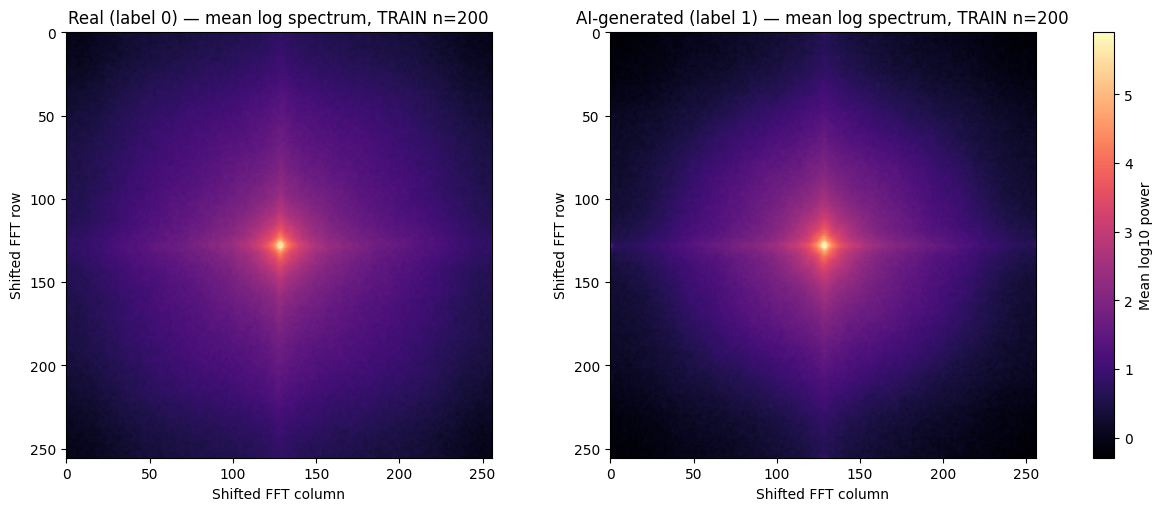

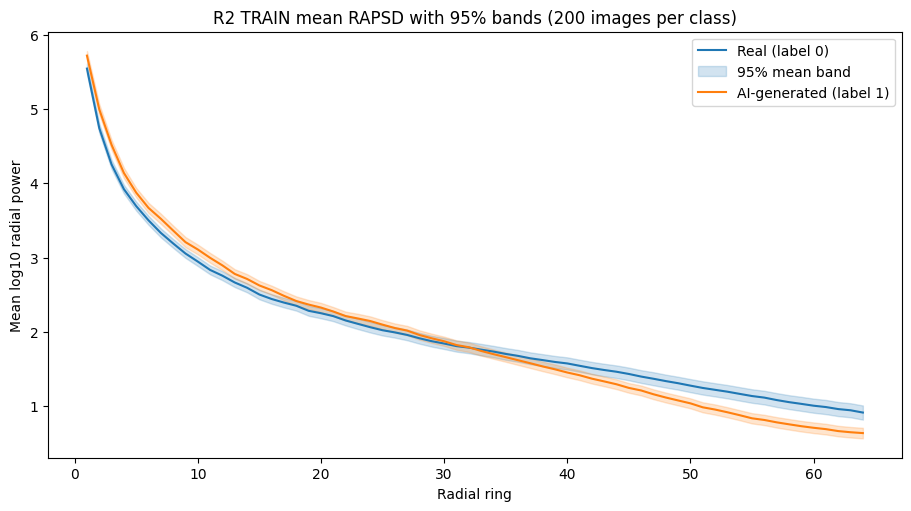

R2 Phase 4 review complete — train-only aggregate diagnostics
{
  "status": "completed_train_only_spectra_review",
  "git_commit": "1170199bbbc62ad32e9c436c3cbad90d2f6d157f",
  "config_sha256": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
  "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
  "active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8",
  "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145",
  "selected_counts": {
    "0": 200,
    "1": 200
  },
  "feature_extraction_or_batch_files_written": false,
  "figures": [
    {
      "name": "phase_4_mean_log_spectrum.png",
      "local_path": "/content/ai-image-fft-detector/reports/r2/figures/phase_4_mean_log_spectrum.png",
      "drive_path": "/content/drive/MyDrive/aidetect/r2/review_backup/phase_4_spectrum_review_20261030T152916Z/phase_4_mean_log_spectrum.png",
      "sha256": "14afb4b01ffa62c0d14a2e

In [ ]:
# R2 Phase 4: aggregate frequency review on deterministic TRAIN rows only.
import hashlib
import json
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/ai-image-fft-detector").resolve()
SRC_DIR = PROJECT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from aidetect.features import power_spectrum, rapsd
from aidetect.io_utils import config_hash, load_config, sha256_of_file
from aidetect.preprocess import R2_PREPROCESS_VERSION, preprocess_image

EXPECTED = {
    "config_hash": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
    "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
    "active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8",
    "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145",
}
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=PROJECT_DIR, text=True).strip()
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_DIR, text=True).strip()
assert branch == "main", f"Expected published main checkout, got {branch!r}"
for relpath in ("config_r2.yaml", "src/aidetect/features.py", "src/aidetect/preprocess.py"):
    changed = subprocess.check_output(["git", "status", "--porcelain", "--", relpath], cwd=PROJECT_DIR, text=True).strip()
    assert not changed, f"Required Phase 4 source is modified in Colab: {relpath}: {changed}"

cfg = load_config(PROJECT_DIR / "config_r2.yaml")
assert config_hash(cfg) == EXPECTED["config_hash"], "R2 config hash mismatch"
assert cfg["preprocess"] == R2_PREPROCESS_VERSION, "Shared R2 preprocessing contract mismatch"
assert cfg["image_size"] == 256 and cfg["rapsd_rings"] == 64 and cfg["seed"] == 42
assert cfg["r2"]["audit_domain"] == "treated_input" and cfg["r2"]["raw_audit_status"] == "blocked"
assert cfg["r2"]["supervisor_signoff"] == "unverified"
frequency = cfg["frequency"]
assert frequency["hann_window"] is True and float(frequency["epsilon"]) == 1e-12

DATA_ROOT = Path(cfg["paths"]["data_root"]).resolve()
ARTIFACTS_ROOT = (PROJECT_DIR / cfg["paths"]["artifacts_root"]).resolve()
AUDIT_PATH = DATA_ROOT / "audit" / "audit_result.json"
ACTIVE_PATH = DATA_ROOT / "audit" / "active_manifest.csv"
SPLITS_PATH = DATA_ROOT / "splits.csv"
PROVENANCE_PATH = ARTIFACTS_ROOT / "splits.json"
SPLIT_DIGEST_PATH = ARTIFACTS_ROOT / "splits.sha256"
actual = {
    "config_hash": config_hash(cfg),
    "splits_sha256": sha256_of_file(SPLITS_PATH),
    "active_manifest_sha256": sha256_of_file(ACTIVE_PATH),
    "audit_result_sha256": sha256_of_file(AUDIT_PATH),
}
provenance = json.loads(PROVENANCE_PATH.read_text(encoding="utf-8"))
split_digest_file = SPLIT_DIGEST_PATH.read_text(encoding="utf-8").strip()
assert actual == EXPECTED, f"R2 source provenance mismatch: {actual}"
assert split_digest_file == EXPECTED["splits_sha256"], "Frozen split digest record mismatch"
for key, value in EXPECTED.items():
    assert provenance.get(key) == value, f"R2 split provenance mismatch for {key}"
audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert audit["status"] == "passed" and audit["protocol"] == "R2"
assert audit["audit_domain"] == "treated_input" and audit["config_hash"] == EXPECTED["config_hash"]
assert audit["active_manifest_sha256"] == EXPECTED["active_manifest_sha256"]
assert audit["final_probe"]["max_accuracy"] <= 0.60 and audit["mixed_label_groups"] == 0
assert audit["raw_audit_status"] == "blocked" and audit["supervisor_signoff"] == "unverified"

# Read split metadata for integrity checks; no validation/test image path is opened.
active = pd.read_csv(ACTIVE_PATH, dtype={"id": str})
frozen = pd.read_csv(SPLITS_PATH, dtype={"id": str, "group_id": str})
assert {"id", "label", "rel_path", "sha256"}.issubset(active.columns), "Active R2 manifest lacks required columns"
assert {"id", "label", "group_id", "split"}.issubset(frozen.columns), "Frozen R2 split lacks required columns"
assert active["id"].is_unique and frozen["id"].is_unique, "Duplicate IDs in R2 manifest or split"
assert frozen["group_id"].notna().all(), "Missing duplicate group IDs"
group_splits = frozen.groupby("group_id")["split"].nunique()
assert group_splits.eq(1).all(), "A duplicate group crosses frozen splits"
split_counts = frozen.groupby(["split", "label"]).size().unstack(fill_value=0)
expected_counts = {"train": {0: 1750, 1: 1750}, "val": {0: 375, 1: 375}, "test": {0: 375, 1: 375}}
for split_name, counts in expected_counts.items():
    assert split_counts.loc[split_name].to_dict() == counts, f"Unexpected frozen {split_name} class counts"

split_meta = frozen[["id", "label", "group_id", "split"]].rename(columns={"label": "split_label"})
joined = active[["id", "label", "rel_path", "sha256"]].merge(
    split_meta, on="id", how="outer", validate="one_to_one", indicator=True
)
assert joined["_merge"].eq("both").all() and len(joined) == 5000, "Active manifest and split IDs differ"
assert joined["label"].astype(int).equals(joined["split_label"].astype(int)), "Active labels disagree with frozen split labels"
train = joined[joined["split"] == "train"].sort_values(["label", "id"], kind="mergesort")
selected = pd.concat([train[train["label"] == label].head(200) for label in (0, 1)], ignore_index=True)
assert selected.groupby("label").size().to_dict() == {0: 200, 1: 200}, "Could not select exactly 200 TRAIN images per class"

REPORTS_DIR = PROJECT_DIR / cfg["paths"]["reports_root"]
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ring_count = int(cfg["rapsd_rings"])
EPSILON = float(frequency["epsilon"])
spectrum_sums = {0: np.zeros((cfg["image_size"], cfg["image_size"]), dtype=np.float64), 1: np.zeros((cfg["image_size"], cfg["image_size"]), dtype=np.float64)}
rapsd_rows = {0: [], 1: []}
selected_records = {0: [], 1: []}
output_min, output_max = 1.0, 0.0

for row in selected.itertuples(index=False):
    label = int(row.label)
    source = (DATA_ROOT / row.rel_path).resolve()
    assert source.is_relative_to(DATA_ROOT), f"TRAIN source escapes R2 data root: {row.id}"
    payload = source.read_bytes()
    source_digest = hashlib.sha256(payload).hexdigest()
    assert source_digest == row.sha256, f"Source checksum mismatch for TRAIN ID {row.id}"
    image = preprocess_image(payload, cfg)
    assert image.shape == (256, 256) and image.dtype == np.float64
    assert np.isfinite(image).all() and float(image.min()) >= 0.0 and float(image.max()) <= 1.0
    output_min = min(output_min, float(image.min()))
    output_max = max(output_max, float(image.max()))
    power = power_spectrum(image, window=frequency["hann_window"])
    log_power = np.log10(np.maximum(power, EPSILON))
    spectrum_sums[label] += log_power
    rapsd_rows[label].append(rapsd(power, rings=ring_count, epsilon=EPSILON))
    selected_records[label].append({"id": str(row.id), "source_sha256": source_digest})

mean_spectra = {label: spectrum_sums[label] / 200.0 for label in (0, 1)}
rapsd_values = {label: np.stack(rapsd_rows[label]) for label in (0, 1)}
assert all(values.shape == (200, ring_count) and np.isfinite(values).all() for values in rapsd_values.values())
vmin = min(float(values.min()) for values in mean_spectra.values())
vmax = max(float(values.max()) for values in mean_spectra.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for axis, label, title in zip(axes, (0, 1), ("Real (label 0)", "AI-generated (label 1)")):
    image_plot = axis.imshow(mean_spectra[label], cmap="magma", vmin=vmin, vmax=vmax)
    axis.set_title(title + " — mean log spectrum, TRAIN n=200")
    axis.set_xlabel("Shifted FFT column")
    axis.set_ylabel("Shifted FFT row")
fig.colorbar(image_plot, ax=axes, label="Mean log10 power")
spectrum_path = FIGURES_DIR / "phase_4_mean_log_spectrum.png"
fig.savefig(spectrum_path, dpi=cfg["audit"]["figure_dpi"])
plt.show()
plt.close(fig)

fig, axis = plt.subplots(figsize=(9, 5), constrained_layout=True)
radii = np.arange(1, ring_count + 1)
for label, color, title in ((0, "tab:blue", "Real (label 0)"), (1, "tab:orange", "AI-generated (label 1)")):
    values = rapsd_values[label]
    mean = values.mean(axis=0)
    half_width = 1.96 * values.std(axis=0, ddof=1) / np.sqrt(values.shape[0])
    axis.plot(radii, mean, color=color, label=title)
    axis.fill_between(radii, mean - half_width, mean + half_width, color=color, alpha=0.2, label="95% mean band" if label == 0 else None)
axis.set_xlabel("Radial ring")
axis.set_ylabel("Mean log10 radial power")
axis.set_title("R2 TRAIN mean RAPSD with 95% bands (200 images per class)")
axis.legend()
rapsd_path = FIGURES_DIR / "phase_4_mean_rapsd.png"
fig.savefig(rapsd_path, dpi=cfg["audit"]["figure_dpi"])
plt.show()
plt.close(fig)

review_id = "phase_4_spectrum_review_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DRIVE_ROOT = DATA_ROOT.parent
DRIVE_BACKUP_ROOT = DRIVE_ROOT / "review_backup"
DRIVE_BACKUP_ROOT.mkdir(parents=True, exist_ok=True)
BACKUP_DIR = DRIVE_BACKUP_ROOT / review_id
BACKUP_DIR.mkdir(parents=False, exist_ok=False)
figure_entries = []
for path in (spectrum_path, rapsd_path):
    target = BACKUP_DIR / path.name
    shutil.copy2(path, target)
    digest = sha256_of_file(path)
    assert sha256_of_file(target) == digest, f"Figure backup checksum mismatch: {path.name}"
    figure_entries.append({"name": path.name, "local_path": str(path), "drive_path": str(target), "sha256": digest})

review_record = {
    "phase": "R2 Phase 4",
    "status": "completed_train_only_spectra_review",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "protocol": "R2",
    "git_branch": branch,
    "git_commit": commit,
    "config_sha256": actual["config_hash"],
    "splits_sha256": actual["splits_sha256"],
    "active_manifest_sha256": actual["active_manifest_sha256"],
    "audit_result_sha256": actual["audit_result_sha256"],
    "audit_domain": "treated_input",
    "raw_audit_status": "blocked",
    "supervisor_signoff": "unverified",
    "preprocess_version": 2,
    "preprocessing_contract": cfg["preprocess"],
    "frequency_settings": {"hann_window": frequency["hann_window"], "epsilon": EPSILON, "rapsd_rings": ring_count},
    "selected_counts": {"0": 200, "1": 200},
    "selected_train_ids_and_source_sha256": {str(label): selected_records[label] for label in (0, 1)},
    "preprocessed_array_contract": {"shape": [256, 256], "dtype": "float64", "range": [0.0, 1.0], "observed_min": output_min, "observed_max": output_max},
    "rapsd_summary": {str(label): {"mean": rapsd_values[label].mean(axis=0).tolist(), "standard_error": (rapsd_values[label].std(axis=0, ddof=1) / np.sqrt(200)).tolist()} for label in (0, 1)},
    "figures": figure_entries,
    "review_backup_directory": str(BACKUP_DIR),
    "validation_test_image_files_opened": False,
    "validation_test_feature_rows_read": False,
    "feature_extraction_or_batch_files_written": False,
    "outputs_are_aggregate_diagnostics_only": True,
}
LOCAL_REVIEW_PATH = REPORTS_DIR / (review_id + ".json")
LOCAL_REVIEW_PATH.write_text(json.dumps(review_record, indent=2, sort_keys=True) + "\n", encoding="utf-8")
DRIVE_REVIEW_PATH = BACKUP_DIR / LOCAL_REVIEW_PATH.name
shutil.copy2(LOCAL_REVIEW_PATH, DRIVE_REVIEW_PATH)
review_sha256 = sha256_of_file(LOCAL_REVIEW_PATH)
assert sha256_of_file(DRIVE_REVIEW_PATH) == review_sha256, "Review record backup checksum mismatch"
sidecar = BACKUP_DIR / (DRIVE_REVIEW_PATH.name + ".sha256")
sidecar.write_text(review_sha256 + "  " + DRIVE_REVIEW_PATH.name + "\n", encoding="utf-8")
assert sidecar.read_text(encoding="utf-8").split()[0] == sha256_of_file(DRIVE_REVIEW_PATH)

print("R2 Phase 4 review complete — train-only aggregate diagnostics")
print(json.dumps({"status": review_record["status"], "git_commit": commit, "config_sha256": actual["config_hash"], "splits_sha256": actual["splits_sha256"], "active_manifest_sha256": actual["active_manifest_sha256"], "audit_result_sha256": actual["audit_result_sha256"], "selected_counts": review_record["selected_counts"], "feature_extraction_or_batch_files_written": False, "figures": figure_entries, "review_record": str(DRIVE_REVIEW_PATH), "review_record_sha256": review_sha256}, indent=2))
print("R2 limitations retained: the original raw audit is blocked; the reviewed audit applies to treated inputs; supervisor sign-off is unverified.")

## Phase 5 - Pixel baseline and feature extraction
This phase extracts both feature sets in resumable batches of the configured size. Train and validation batches may be read for checks; test features are written to `features_root/test_sealed/` but are never read here. The official reader refuses test rows until `artifacts/FREEZE.lock` exists in Phase 7.

In [4]:
"""R2 Phase 5 Colab preparation; safe after runtime variable loss."""
from pathlib import Path
import os
import sys
import json
import subprocess
from datetime import datetime, timezone
import numpy as np
import pandas as pd

PROJECT_DIR = Path('/content/ai-image-fft-detector')
assert (PROJECT_DIR / 'config_r2.yaml').is_file(), 'Existing research checkout is missing'
sys.path.insert(0, str(PROJECT_DIR / 'src'))
sys.path.insert(0, str(PROJECT_DIR))
from aidetect.io_utils import load_config, config_hash, sha256_of_file
from aidetect.feature_extraction import read_feature_batches, _validate_existing_batch, _id_digest
from scripts.extract_features import _load_rows

R2_CONFIG_PATH = PROJECT_DIR / 'config_r2.yaml'
cfg = load_config(R2_CONFIG_PATH)
def _config_path(key):
    path = Path(cfg['paths'][key])
    return path if path.is_absolute() else PROJECT_DIR / path
DATA_ROOT, FEATURES_ROOT, REPORTS_ROOT, ARTIFACTS_ROOT = (
    _config_path(k) for k in ('data_root', 'features_root', 'reports_root', 'artifacts_root'))
FREEZE_LOCK = ARTIFACTS_ROOT / 'FREEZE.lock'
assert not FREEZE_LOCK.exists(), 'Phase 5 cannot run after freeze'
assert not list((ARTIFACTS_ROOT / 'models').glob('*.joblib')), 'Unexpected existing models'
EXPECTED = {
    'config_sha256': 'ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6',
    'splits_sha256': '1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93',
    'active_manifest_sha256': '2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8',
    'audit_result_sha256': '0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145'}
actual = {
    'config_sha256': config_hash(cfg),
    'splits_sha256': sha256_of_file(DATA_ROOT / 'splits.csv'),
    'active_manifest_sha256': sha256_of_file(DATA_ROOT / 'audit/active_manifest.csv'),
    'audit_result_sha256': sha256_of_file(DATA_ROOT / 'audit/audit_result.json')}
assert actual == EXPECTED, (actual, EXPECTED)
audit = json.loads((DATA_ROOT / 'audit/audit_result.json').read_text())
assert audit['status'] == 'passed' and audit['protocol'] == 'R2'
assert audit['config_hash'] == actual['config_sha256']
record = json.loads((ARTIFACTS_ROOT / 'splits.json').read_text())
for key in ('splits_sha256', 'active_manifest_sha256', 'audit_result_sha256'):
    assert record[key] == actual[key], key
assert record['config_hash'] == actual['config_sha256']
assert (ARTIFACTS_ROOT / 'splits.sha256').read_text().strip() == actual['splits_sha256']
frozen = pd.read_csv(DATA_ROOT / 'splits.csv', dtype={'id': str, 'group_id': str})
assert frozen.groupby('group_id')['split'].nunique().max() == 1
counts = frozen.groupby(['split', 'label']).size().to_dict()
assert counts == {('train',0):1750, ('train',1):1750, ('val',0):375, ('val',1):375, ('test',0):375, ('test',1):375}
for split in ('train', 'val', 'test'):
    assert len(_load_rows(DATA_ROOT, split, expected_active_digest=actual['active_manifest_sha256'])) == int((frozen['split'] == split).sum())
P5_BACKUP = DATA_ROOT.parent / 'review_backup' / ('phase_5_extraction_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
P5_BACKUP.mkdir(parents=True, exist_ok=False)
cli_env = os.environ.copy()
cli_env['PYTHONPATH'] = str(PROJECT_DIR / 'src') + os.pathsep + str(PROJECT_DIR)
P5_RESULTS = {}
print('R2 Phase 5 prerequisites VERIFIED', json.dumps(actual, indent=2))
print('Frozen class counts:', counts)
print('Batch size:', cfg['batch_size'], 'Feature root:', FEATURES_ROOT)
print('Evidence directory:', P5_BACKUP)


R2 Phase 5 prerequisites VERIFIED {
  "config_sha256": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
  "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
  "active_manifest_sha256": "2af4d01ee69adadc0f28c741ad2bafed846d73c958b0f114efca939122ee05e8",
  "audit_result_sha256": "0ec413d2f64e3e9da9da6e97be41c5bf9071a061cf987a472bacdafaa7fce145"
}
Frozen class counts: {('test', 0): 375, ('test', 1): 375, ('train', 0): 1750, ('train', 1): 1750, ('val', 0): 375, ('val', 1): 375}
Batch size: 500 Feature root: /content/drive/MyDrive/aidetect/r2/features
Evidence directory: /content/drive/MyDrive/aidetect/r2/review_backup/phase_5_extraction_20261031T013553Z


In [5]:
"""Run only train and validation extraction, preserving exact CLI outputs."""
for split in ('train', 'val'):
    print('Extracting R2', split, flush=True)
    result = subprocess.run([sys.executable, '-u', 'scripts/extract_features.py', '--config', str(R2_CONFIG_PATH), '--split', split], cwd=PROJECT_DIR, env=cli_env, capture_output=True, text=True)
    (P5_BACKUP / (split + '_extraction.txt')).write_text(result.stdout + result.stderr)
    print(result.stdout, result.stderr, flush=True)
    result.check_returncode()
    P5_RESULTS[split] = json.loads(result.stdout)


Extracting R2 train
{
  "batches": 7,
  "config_hash": "ac92656ca11539bf8aaa7c6c89d9851ddf006ed4fc514a99ba6b2e9bae24d7d6",
  "output_dir": "/content/drive/MyDrive/aidetect/r2/features/train",
  "rows": 3500,
  "skipped_batches": 2,
  "split": "train",
  "splits_sha256": "1e823b5df253951bc2a7221b618fc7c0e5716f85066d509a3d9442c56ccfef93",
  "test_features_written_only": false,
  "timings": [
    {
      "batch_index": 0,
      "rows": 500,
      "seconds": 0.0,
      "status": "skipped"
    },
    {
      "batch_index": 1,
      "rows": 500,
      "seconds": 0.0,
      "status": "skipped"
    },
    {
      "batch_index": 2,
      "rows": 500,
      "seconds": 270.122657,
      "status": "written"
    },
    {
      "batch_index": 3,
      "rows": 500,
      "seconds": 265.945187,
      "status": "written"
    },
    {
      "batch_index": 4,
      "rows": 500,
      "seconds": 243.989718,
      "status": "written"
    },
    {
      "batch_index": 5,
      "rows": 500,
      "seconds": 

In [6]:
"""Deterministic test extraction only; never inspect feature values."""
assert set(P5_RESULTS) >= {'train', 'val'}, 'Run train and validation extraction first'
print('Writing R2 test features to test_sealed; values remain sealed.', flush=True)
result = subprocess.run([sys.executable, '-u', 'scripts/extract_features.py', '--config', str(R2_CONFIG_PATH), '--split', 'test'], cwd=PROJECT_DIR, env=cli_env, capture_output=True, text=True)
(P5_BACKUP / 'test_extraction.txt').write_text(result.stdout + result.stderr)
print(result.stdout, result.stderr, flush=True)
result.check_returncode()
P5_RESULTS['test'] = json.loads(result.stdout)


Writing R2 test features to test_sealed; values remain sealed.


KeyboardInterrupt: 

In [ ]:
"""Verify readable features and sealed provenance; save Phase 5 evidence."""
import pyarrow.parquet as pq
checks = {}
for split in ('train', 'val', 'test'):
    rows = _load_rows(DATA_ROOT, split, expected_active_digest=actual['active_manifest_sha256']).sort_values('id')
    folder = FEATURES_ROOT / ('test_sealed' if split == 'test' else split)
    paths = sorted(folder.glob('batch_*.parquet'))
    assert len(paths) == (len(rows) + cfg['batch_size'] - 1) // cfg['batch_size']
    total = 0
    for index, path in enumerate(paths):
        batch = rows.iloc[index * cfg['batch_size']:(index + 1) * cfg['batch_size']]
        _validate_existing_batch(path, cfg_hash=actual['config_sha256'], splits_hash=actual['splits_sha256'], split=split, batch_index=index, batch_ids_hash=_id_digest(batch['id']))
        metadata = pq.read_metadata(path)
        assert metadata.num_rows == len(batch)
        total += metadata.num_rows
    checks[split] = {'rows': total, 'batches': len(paths), 'metadata_matches': True}
    if split != 'test':
        frame = read_feature_batches(FEATURES_ROOT, split, artifacts_root=ARTIFACTS_ROOT)
        assert set(frame['id']) == set(rows['id']) and len(frame) == len(rows)
        expected_rows = rows.set_index('id')
        for column in ('label', 'group_id'):
            assert frame.set_index('id')[column].sort_index().equals(expected_rows[column].sort_index())
        assert np.isfinite(frame.select_dtypes(include=[np.number]).to_numpy()).all()
        assert sum(c.startswith('pixel_') for c in frame.columns) == 1024
        assert sum(c.startswith('rapsd_ring_') for c in frame.columns) == 64
        checks[split]['all_numeric_finite'] = True
        checks[split]['pixel_features'] = 1024
        checks[split]['rapsd_rings'] = 64
        del frame
try:
    read_feature_batches(FEATURES_ROOT, 'test', artifacts_root=ARTIFACTS_ROOT)
except PermissionError as error:
    print('Expected sealed-test denial:', error)
else:
    raise AssertionError('Test reader did not enforce seal')
test_run = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/test_pixel_baseline.py', 'tests/test_feature_extraction.py', 'tests/test_r2.py'], cwd=PROJECT_DIR, env=cli_env, capture_output=True, text=True)
(P5_BACKUP / 'pytest.txt').write_text(test_run.stdout + test_run.stderr)
print('Focused Colab tests:', test_run.returncode, test_run.stdout, test_run.stderr)
test_run.check_returncode()
assert not FREEZE_LOCK.exists()
assert sha256_of_file(DATA_ROOT / 'splits.csv') == actual['splits_sha256']
evidence = {'status': 'completed', 'phase': 5, 'protocol': 'R2', **actual, 'checks': checks, 'extraction': P5_RESULTS, 'test_feature_values_read': False, 'sealed_reader_denied': True, 'training_started': False, 'freeze_created': False, 'evaluation_started': False, 'supervisor_signoff': 'unverified', 'original_raw_audit': 'blocked', 'audit_domain': 'treated_input', 'pytest_output': test_run.stdout, 'backup': str(P5_BACKUP)}
report = P5_BACKUP / 'phase_5_r2_checks.json'
report.write_text(json.dumps(evidence, indent=2, sort_keys=True))
manifest = {p.name: sha256_of_file(p) for p in P5_BACKUP.iterdir() if p.is_file()}
(P5_BACKUP / 'sha256.json').write_text(json.dumps(manifest, indent=2, sort_keys=True))
print('R2 PHASE 5 COMPLETE', json.dumps(evidence, indent=2, sort_keys=True))
print('Review record SHA256:', sha256_of_file(report))
print('STOP before Phase 6. No training, freeze or evaluation ran.')


## Phase 6 - Train and select models
Run only after the team has reviewed the Phase 2 immutable split and the Phase 5 train/validation feature checks. This phase reads train and validation features only. It does not access `test_sealed`; do not create the Phase 7 freeze lock yet.
The script selects frequency settings on train/validation, tunes the six matched pipelines on train folds, reports validation metrics, and records the validation-selected frequency model. Feature importance is descriptive only.


In [ ]:
"""R2 Phase 6 readiness, also usable after a stopped runtime is replaced."""
from pathlib import Path
from datetime import datetime, timezone
import json
import os
import subprocess
import sys

PROJECT_DIR = Path('/content/ai-image-fft-detector')
sys.path.insert(0, str(PROJECT_DIR / 'src'))
from aidetect.io_utils import config_hash, load_config, sha256_of_file

R2_CONFIG_PATH = PROJECT_DIR / 'config_r2.yaml'
cfg = load_config(R2_CONFIG_PATH)
def _phase6_path(key):
    path = Path(cfg['paths'][key])
    return path if path.is_absolute() else PROJECT_DIR / path
DATA_ROOT, FEATURES_ROOT, REPORTS_ROOT, ARTIFACTS_ROOT = (
    _phase6_path(key) for key in ('data_root', 'features_root', 'reports_root', 'artifacts_root'))
FREEZE_LOCK = ARTIFACTS_ROOT / 'FREEZE.lock'
summary = json.loads((PROJECT_DIR / 'reports/phase_5_r2_checks.json').read_text())
assert summary['status'] == 'completed', 'Reviewed Phase 5 completion is required'
report = Path(summary['drive_backup']) / 'phase_5_r2_checks.json'
assert sha256_of_file(report) == summary['review_record_sha256'], 'Phase 5 record changed'
evidence = json.loads(report.read_text())
assert evidence['status'] == 'completed' and evidence['phase'] == 5
assert evidence['sealed_reader_denied'] and not evidence['test_feature_values_read']
assert config_hash(cfg) == evidence['config_sha256']
assert sha256_of_file(DATA_ROOT / 'splits.csv') == evidence['splits_sha256']
for filename, key in (('active_manifest.csv', 'active_manifest_sha256'),
                      ('audit_result.json', 'audit_result_sha256')):
    assert sha256_of_file(DATA_ROOT / 'audit' / filename) == evidence[key]
EXPECTED = {'config_sha256': evidence['config_sha256'], 'splits_sha256': evidence['splits_sha256']}
assert not FREEZE_LOCK.exists()
assert not (ARTIFACTS_ROOT / 'EVALUATION_STARTED.json').exists()
if 'p6_process' in globals():
    assert p6_process.poll() is not None, 'The previous training subprocess is still active'
P6_CHECKPOINT_ROOT = DATA_ROOT.parent / 'phase6_checkpoints'
assert not (P6_CHECKPOINT_ROOT / 'running.lock').exists(), 'Checkpoint writer is active or left a stale lock; inspect before resuming'
if not (P6_CHECKPOINT_ROOT / 'manifest.json').exists():
    assert not (ARTIFACTS_ROOT / 'training_results.json').exists(), 'Existing results require review before any rerun'
    assert not list((ARTIFACTS_ROOT / 'models').glob('*.joblib')), 'Existing models require review'
# The CLI verifies checkpoint ownership, input/code/version hashes and final outputs before reuse.
assert cfg['cv_folds'] == 5 and cfg['search_iters'] == 30 and cfg['seed'] == 42
assert cfg['training']['search_n_jobs'] == 1
cli_env = os.environ.copy()
cli_env['PYTHONPATH'] = str(PROJECT_DIR / 'src') + os.pathsep + str(PROJECT_DIR)
P6_BACKUP = DATA_ROOT.parent / 'review_backup' / ('phase_6_training_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
P6_BACKUP.mkdir(parents=True, exist_ok=False)
P6_START = {'status': 'ready', 'config_hash': config_hash(cfg), 'splits_sha256': EXPECTED['splits_sha256'], 'phase5_record_sha256': sha256_of_file(report), 'test_features_read': False, 'backup': str(P6_BACKUP), 'checkpoint_dir': str(P6_CHECKPOINT_ROOT)}
(P6_BACKUP / 'start.json').write_text(json.dumps(P6_START, indent=2, sort_keys=True))
print('R2 PHASE 6 READY', json.dumps(P6_START, indent=2))
print('Six matched CPU pipelines; five shared folds; 30 trials per model. Checkpoints on Drive; test stays sealed.')


In [ ]:
"""Run authorized R2 training; preserve outputs on Drive when it completes."""
import shutil
assert P6_START['status'] == 'ready'
assert not FREEZE_LOCK.exists()
P6_COMMAND = [sys.executable, '-u', 'scripts/train_models.py', '--config', str(R2_CONFIG_PATH), '--checkpoint-dir', str(P6_CHECKPOINT_ROOT)]
with (P6_BACKUP / 'training.log').open('x') as p6_log:
    p6_process = subprocess.Popen(P6_COMMAND, cwd=PROJECT_DIR, env=cli_env, stdout=p6_log, stderr=subprocess.STDOUT, text=True)
    P6_START.update(status='running', pid=p6_process.pid, command=P6_COMMAND, started_utc=datetime.now(timezone.utc).isoformat())
    (P6_BACKUP / 'start.json').write_text(json.dumps(P6_START, indent=2, sort_keys=True))
    print('R2 PHASE 6 STARTED', json.dumps(P6_START, indent=2), flush=True)
    p6_exit = p6_process.wait()
print('Training exit:', p6_exit, flush=True)
P6_START['exit_code'] = p6_exit
P6_START['status'] = 'completed' if p6_exit == 0 else 'failed'
(P6_BACKUP / 'start.json').write_text(json.dumps(P6_START, indent=2, sort_keys=True))
if p6_exit:
    print((P6_BACKUP / 'training.log').read_text()[-12000:])
    raise RuntimeError('R2 Phase 6 failed; preserve log and inspect before rerunning')
p6_result = json.loads((ARTIFACTS_ROOT / 'training_results.json').read_text())
assert len(p6_result['models']) == 6 and p6_result['test_features_read'] is False
for source_root, target_folder in ((ARTIFACTS_ROOT, 'artifacts'), (REPORTS_ROOT, 'reports')):
    for source in source_root.rglob('*'):
        if source.is_file():
            target = P6_BACKUP / target_folder / source.relative_to(source_root)
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, target)
            assert sha256_of_file(source) == sha256_of_file(target)
p6_hashes = {str(p.relative_to(P6_BACKUP)): sha256_of_file(p) for p in P6_BACKUP.rglob('*') if p.is_file()}
(P6_BACKUP / 'sha256.json').write_text(json.dumps(p6_hashes, indent=2, sort_keys=True))
print('R2 PHASE 6 COMPLETED. Review metrics and models before Phase 7.', flush=True)
print((REPORTS_ROOT / 'phase_6_results.md').read_text(), flush=True)
print('Backup:', P6_BACKUP, flush=True)
print('STOP: no freeze or test evaluation authorized.', flush=True)


In [ ]:
import json
from IPython.display import Markdown, display

result = json.loads((ARTIFACTS_ROOT / "training_results.json").read_text())
assert len(result["models"]) == 6
assert result["test_features_read"] is False
assert not (ARTIFACTS_ROOT / "FREEZE.lock").exists()
assert (ARTIFACTS_ROOT / "feature_choice.json").is_file()
assert (ARTIFACTS_ROOT / "primary_model.json").is_file()
display(Markdown((PROJECT_DIR / cfg["paths"]["reports_root"] / "phase_6_results.md").read_text()))
print("Selected frequency settings:", result["feature_choice"]["r0"], result["feature_choice"]["k_mad"])
print("Primary model:", result["primary_model"]["artifact_key"])
print("CV folds / searches per model:", result["cv_folds"], result["search_iterations_per_model"])


## STOP - Phase 6 team review
Review train/validation row counts, feature-choice scores, all six CV and validation metrics, saved versions/models, and descriptive importance plots. Confirm the split groups remain separated and check GitHub Actions. Agree and record the practical-use target in `reports/practical_target.md` before Phase 7. Keep real-data outputs and supervisor decisions pending until supplied; do not open `test_sealed` or create `FREEZE.lock` in this phase.

## Phase 6 completed and independently verified — 31 October 2026

The approved **config_r2_fast_rf_t4.yaml** run completed at **15:15:09 IST**; independent verification finished **15:15:25 IST**. All six models, 60 eligible candidate records and 20 Drive backup hashes passed; all validation metrics were reproduced. The revised run took **9m43s with three verified models reused**; the overall earlier-attempt/switch workflow took **47m02s**.

Primary model: **frequency RBF SVM**, validation accuracy **80.67% (605/750)**, ROC-AUC **0.883072**, Brier **0.135568**; selected **r0=120, k_mad=5**. These are validation metrics only. Final RF ranges: **100–300 trees / sqrt features** for both feature sets; 3 folds and 10 candidates for all six models.

Drive model/report backup: `aidetect/r2/review_backup/r2_fast_rf_t4_training_20261031T093525Z`. Completion record SHA-256: `5eb86a77101a2fdd7afc0967b3cf1cd388781415236782f6deb4549289296025`. See `reports/phase_6_fast_rf_t4_report.md` and `reports/phase_6_fast_rf_t4_checks.json`.

**STOP. Do not rerun training or run all notebook cells.** Test features remain sealed. The raw audit remains blocked; supervisor acceptance and practical-target agreement are unverified. Phase 7 requires separate authorization.


Latest approved T4 profile: **config_r2_fast_rf_t4.yaml** (RF: 100-300 trees, sqrt features). The earlier broad RF profiles are retained as historical alternatives. Once a run completes, do not rerun it; see the Phase 6 completion report before any next phase.

## Approved faster Colab execution (31 October 2026)
Use CPU for acquisition, audit, preprocessing, spectra, extraction, evaluation and reporting. These tasks use the existing CPU libraries. Do not rerun completed phases to change runtime. Phase 5 optionally accepts `--workers 2`; outputs remain ordered, checksummed and sealed. GPU acceleration is optional for XGBoost only.

Phase 6 fast amendment: 3 shared stratified folds, 10 sampled candidates per model (180 search fits), 3-fold sigmoid SVM calibration, the same six pipelines/search ranges/seed/feature-choice grid. This is a user-approved reduction of the original 5-fold/30-candidate protocol, not equivalent evidence of optimization quality. Original configs and records remain unchanged. CPU and T4 profiles have independent outputs/checkpoints. Keep this choice fixed before evaluation. No Phase 7 authorization is inferred.

Run setup once, then these cells only. Never use Run all. Existing completed runs refuse rerunning. A stale lock requires confirmation that its old runtime stopped before removing only that lock. See `docs/COLAB_PERFORMANCE.md`.


In [ ]:
from pathlib import Path
import subprocess, sys, os, json
PROJECT_DIR = Path('/content/ai-image-fft-detector')
os.chdir(PROJECT_DIR)
FAST_CONFIG = PROJECT_DIR / 'config_r2_fast_rf_t4.yaml'  # latest user-approved T4 / narrower RF profile
fast_env = os.environ.copy()
fast_env['PYTHONPATH'] = str(PROJECT_DIR / 'src') + os.pathsep + str(PROJECT_DIR / 'scripts')
fast_env.update(OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1', NUMEXPR_NUM_THREADS='1')
# This verifies the reviewed Phase 5 record and frozen provenance; no extraction or test reads.
processes = subprocess.check_output(['ps', '-eo', 'pid,args'], text=True)
assert not any('scripts/train_models.py' in line or 'scripts/run_fast_training.py' in line for line in processes.splitlines()), 'A training process is already running'
subprocess.run([sys.executable, 'scripts/prepare_fast_training.py', '--config', str(FAST_CONFIG)], cwd=PROJECT_DIR, env=fast_env, check=True)


In [ ]:
# Optional timing only. Reads TRAIN batches; emits no research metrics.
BENCHMARK_PATH = Path('/content/drive/MyDrive/aidetect/r2/review_backup') / ('cpu_benchmark_' + __import__('datetime').datetime.now(__import__('datetime').timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '.json')
subprocess.run([sys.executable, '-u', 'scripts/benchmark_training.py', '--config', str(FAST_CONFIG), '--output', str(BENCHMARK_PATH)], cwd=PROJECT_DIR, env=fast_env, check=True)
print(BENCHMARK_PATH.read_text())


In [ ]:
# Launches Phase 6 only. The runner independently backs up all six completed models/results.
assert not ('fast_process' in globals() and fast_process.poll() is None), 'Fast training is already running'
assert not any('scripts/train_models.py' in line or 'scripts/run_fast_training.py' in line for line in subprocess.check_output(['ps', '-eo', 'pid,args'], text=True).splitlines()), 'Another training process is active'
FAST_LAUNCH_LOG = Path('/content/drive/MyDrive/aidetect/r2') / ('fast_launch_' + __import__('datetime').datetime.now(__import__('datetime').timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '.log')
with FAST_LAUNCH_LOG.open('x') as stream:
    fast_process = subprocess.Popen([sys.executable, '-u', 'scripts/run_fast_training.py', '--config', str(FAST_CONFIG)], cwd=PROJECT_DIR, env=fast_env, stdout=stream, stderr=subprocess.STDOUT, start_new_session=True)
print('Fast Phase 6 runner PID:', fast_process.pid)
print('Launch log:', FAST_LAUNCH_LOG)
print('STOP: no freeze/test evaluation queued. Use the status cell; do not rerun launch.')


In [ ]:
# Read-only status; safe while the training subprocess is running.
from pathlib import Path
import json
root = Path('/content/drive/MyDrive/aidetect/r2')
for folder in sorted((root / 'review_backup').glob('r2_fast*_training_*'))[-2:]:
    print(folder)
    for name in ('start.json', 'training.log'):
        path = folder / name
        if path.is_file(): print(name, path.read_text()[-3000:])
for folder in sorted(root.glob('r2_fast*_phase6_checkpoints')):
    path = folder / 'status.json'
    if path.is_file(): print(folder, path.read_text())
print('STOP before Phase 7. Review actual completed outputs and practical target first.')


## Phase 7 - Freeze and single test evaluation
Run only after the team has reviewed the real Phase 6 training outputs and committed them with the agreed practical-use decision. This section first creates a hash lock without parsing the sealed test Parquet rows. Commit and push that lock to `main` before running the separate one-time evaluator.

The completed Phase 6 run uses `config_r2_fast_rf_t4.yaml` and nested roots under `artifacts/r2_fast_rf_t4/` and `reports/r2_fast_rf_t4/`. The evaluator creates `artifacts/r2_fast_rf_t4/EVALUATION_STARTED.json` before opening test rows. If it fails after creating that marker, do not rerun it; preserve the marker and ask the supervisor how to proceed. No test data or research result is included in this notebook by default.

In [ ]:
import json
import shutil
from aidetect.freeze import validate_practical_target
from aidetect.io_utils import config_hash, sha256_of_file

PHASE7_CONFIG = PROJECT_DIR / "config_r2_fast_rf_t4.yaml"
EXPECTED_PHASE6_CONFIG_SHA256 = "46dbd2c248195aae6eef02a2219a56747090b4bb5f88e3cfb372ced68515766f"
cfg = load_config(PHASE7_CONFIG)
assert config_hash(cfg) == EXPECTED_PHASE6_CONFIG_SHA256, "The Phase 6 config changed; stop and review provenance"
def project_path(value):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (PROJECT_DIR / path).resolve()
ARTIFACTS_ROOT = project_path(cfg["paths"]["artifacts_root"])
REPORTS_ROOT = project_path(cfg["paths"]["reports_root"])
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=PROJECT_DIR, text=True).strip()
status = subprocess.check_output(["git", "status", "--porcelain", "--untracked-files=all"], cwd=PROJECT_DIR, text=True).strip()
assert branch == "main", f"Phase 7 must run on main, not {branch}"
assert not status, "Commit and push reviewed Phase 6 outputs and the practical target before freezing"
assert not (ARTIFACTS_ROOT / "FREEZE.lock").exists(), "A freeze lock already exists"
assert not (ARTIFACTS_ROOT / "EVALUATION_STARTED.json").exists(), "The one-time evaluation has already started"
for name in ("splits.sha256", "feature_choice.json", "primary_model.json", "versions.json", "training_results.json"):
    assert (ARTIFACTS_ROOT / name).is_file(), f"Missing Phase 6 output: {name}"
model_names = [f"{feature_set}_{model}.joblib" for feature_set in ("frequency", "pixel") for model in ("svm", "rf", "xgb")]
model_files = {name: ARTIFACTS_ROOT / "models" / name for name in model_names}
assert (REPORTS_ROOT / "practical_target.md").is_file(), f"Missing practical target: {REPORTS_ROOT / 'practical_target.md'}"
# Restore only the exact reviewed Drive backup. Never create a new backup from local binaries here.
DRIVE_ROOT = Path("/content/drive/MyDrive/aidetect")
MODEL_BACKUP_ROOT = DRIVE_ROOT / "r2/review_backup/r2_fast_rf_t4_training_20261031T093525Z/artifacts/models"
MODEL_BACKUP_MANIFEST = PROJECT_DIR / "reports/phase_6_fast_rf_t4_backup_hashes.json"
assert MODEL_BACKUP_MANIFEST.is_file(), f"Missing committed backup manifest: {MODEL_BACKUP_MANIFEST}"
manifest = json.loads(MODEL_BACKUP_MANIFEST.read_text(encoding="utf-8"))
for name, local_path in model_files.items():
    backup_path = MODEL_BACKUP_ROOT / name
    manifest_key = f"artifacts/models/{name}"
    assert manifest_key in manifest, f"Missing verified hash for {name}"
    expected_hash = manifest[manifest_key]
    assert backup_path.is_file(), f"Missing verified Drive model backup: {backup_path}"
    if not local_path.exists():
        local_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(backup_path, local_path)
    assert sha256_of_file(backup_path) == expected_hash, f"Drive model backup changed: {name}"
    assert sha256_of_file(local_path) == expected_hash, f"Local model differs from reviewed backup: {name}"

target = validate_practical_target(REPORTS_ROOT / "practical_target.md")
print("Ready on main commit:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_DIR, text=True).strip())
print("Agreed minimum validation accuracy:", target["minimum_validation_accuracy"])
print("Decision date:", target["decision_date"])
print("This preflight did not open test feature rows or values.")

In [ ]:
subprocess.run([sys.executable, "scripts/freeze.py", "--config", str(PHASE7_CONFIG)], cwd=PROJECT_DIR, check=True)

### STOP before test evaluation
Inspect `artifacts/r2_fast_rf_t4/FREEZE.lock`, then commit and push it to `main`. The evaluator refuses an uncommitted lock or dirty checkout. Do not run the next cell until the lock commit is on `main` and the checkout is clean.

```text
git add artifacts/r2_fast_rf_t4/FREEZE.lock
git commit -m "Freeze Phase 7 evaluation inputs"
git push origin main
git status --short --branch
```

In [ ]:
# A fresh Colab runtime may need to restore ignored model binaries from the exact reviewed Drive backup. Never restore or rerun after an evaluation marker exists.
import json
import shutil
from aidetect.io_utils import config_hash, sha256_of_file
PHASE7_CONFIG = PROJECT_DIR / "config_r2_fast_rf_t4.yaml"
EXPECTED_PHASE6_CONFIG_SHA256 = "46dbd2c248195aae6eef02a2219a56747090b4bb5f88e3cfb372ced68515766f"
cfg = load_config(PHASE7_CONFIG)
assert config_hash(cfg) == EXPECTED_PHASE6_CONFIG_SHA256, "The Phase 6 config changed; stop and review provenance"
def project_path(value):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (PROJECT_DIR / path).resolve()
ARTIFACTS_ROOT = project_path(cfg["paths"]["artifacts_root"])
REPORTS_ROOT = project_path(cfg["paths"]["reports_root"])
assert not (ARTIFACTS_ROOT / "EVALUATION_STARTED.json").exists(), "Evaluation already started; do not rerun"
assert not any((REPORTS_ROOT / name).exists() for name in ("results.json", "results.md", "test_predictions.csv")), "Evaluation outputs already exist; do not rerun"
DRIVE_ROOT = Path("/content/drive/MyDrive/aidetect")
MODEL_BACKUP_ROOT = DRIVE_ROOT / "r2/review_backup/r2_fast_rf_t4_training_20261031T093525Z/artifacts/models"
manifest = json.loads((PROJECT_DIR / "reports/phase_6_fast_rf_t4_backup_hashes.json").read_text(encoding="utf-8"))
model_names = [f"{feature_set}_{model}.joblib" for feature_set in ("frequency", "pixel") for model in ("svm", "rf", "xgb")]
for name in model_names:
    local_path = ARTIFACTS_ROOT / "models" / name
    backup_path = MODEL_BACKUP_ROOT / name
    manifest_key = f"artifacts/models/{name}"
    assert manifest_key in manifest, f"Missing verified hash for {name}"
    assert backup_path.is_file(), f"Missing verified Drive model backup: {backup_path}"
    if not local_path.exists():
        local_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(backup_path, local_path)
    expected_hash = manifest[manifest_key]
    assert sha256_of_file(backup_path) == expected_hash, f"Drive model backup changed: {name}"
    assert sha256_of_file(local_path) == expected_hash, f"Local model differs from reviewed backup: {name}"
subprocess.run([sys.executable, "scripts/evaluate_test.py", "--config", str(PHASE7_CONFIG)], cwd=PROJECT_DIR, check=True)

## STOP - Phase 7 team review
Review `reports/r2_fast_rf_t4/results.md`, `reports/r2_fast_rf_t4/results.json`, `reports/r2_fast_rf_t4/test_predictions.csv`, and `artifacts/r2_fast_rf_t4/EVALUATION_STARTED.json`. Hand-check at least one accuracy using `(TP + TN) / n` from its confusion matrix. Confirm all six models appear and H1, H1a, and H1b include their preregistered decisions, including non-rejections. Compare the primary test accuracy with the practical target recorded before freeze.

After a successful single run, commit and push the marker and result files to `main`. Do not rerun the evaluator. If it failed after the start marker appeared, do not rerun; retain the marker and contact the supervisor. Any later analysis must be labeled exploratory. Stop here until the team has reviewed the actual outputs and explicitly approves Phase 8.

## Phase 8 - Run the React prototype locally
The user authorized Phase 8 code while real-data review remains pending. See app/README.md and reports/phase_8_report.md. On the laptop: install Python requirements; run npm ci and npm run build in app/frontend; start python -m uvicorn app.backend.main:app --host 127.0.0.1 --port 8000 from the repository root. Open http://127.0.0.1:8000.

Use the reviewed Phase 7 model bundle/config/source for real predictions. Missing artifacts show an honest unavailable-model state. Check five reviewed images for probability parity, a text file renamed .jpg for a clear error, and note out-of-scope phone/screenshot behavior. Uploads remain in memory. Verify keyboard and physical mobile behavior. STOP after Phase 8 review; Phase 9 uses saved outputs only.

## Phase 9 - Report pack and reproducibility
TODO: add this phase's commands only when authorized. Read AGENTS.md and the PRD first.